# DCCM — MUC2 Long PTS Glycosylated vs Non-glycosylated

Dynamic Cross-Correlation Matrix for the 115-residue Long PTS region (residues 1378–1492).
- **+1** = residues always move together (correlated)
- **−1** = residues always move in opposite directions (anti-correlated)
- **0** = uncorrelated motion

Glycan attachment sites marked on each axis (glycosylated panels only).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import TwoSlopeNorm

base       = "/home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/"
output_dir = "/home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots"
os.makedirs(output_dir, exist_ok=True)

CLR_GLY = "#2E86AB"
CLR_NOG = "#A23B72"

RES_OFFSET = 1377          # residue 0-index → residue number = i + RES_OFFSET + 1
N_RES      = 115
res_nums   = np.arange(N_RES) + RES_OFFSET + 1   # 1378 … 1492

# Glycan attachment residues (residue numbers)
GLYCAN_RES = [1379,1383,1386,1389,1393,1397,1402,1406,1409,1412,
               1416,1420,1425,1429,1432,1435,1439,1443,1448,1452,
               1455,1458,1462,1466,1471,1475,1478,1481,1485,1489]
# Convert to 0-based matrix indices
glycan_idx = [r - (RES_OFFSET + 1) for r in GLYCAN_RES]

print("Ready. Output:", output_dir)
print(f"Residues: {res_nums[0]} – {res_nums[-1]}  ({N_RES} total)")
print(f"Glycan sites (0-indexed): {glycan_idx}")

Ready. Output: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots
Residues: 1378 – 1492  (115 total)
Glycan sites (0-indexed): [1, 5, 8, 11, 15, 19, 24, 28, 31, 34, 38, 42, 47, 51, 54, 57, 61, 65, 70, 74, 77, 80, 84, 88, 93, 97, 100, 103, 107, 111]


## Load DCCM Matrices

In [2]:
dccm_gly = np.loadtxt(base + "muc2_dccm_glyc.txt")
dccm_nog = np.loadtxt(base + "muc2_dccm_noglyc.txt")

print(f"Glycosylated shape : {dccm_gly.shape}  min={dccm_gly.min():.3f}  max={dccm_gly.max():.3f}")
print(f"Non-glycosylated shape: {dccm_nog.shape}  min={dccm_nog.min():.3f}  max={dccm_nog.max():.3f}")

dccm_diff = dccm_gly - dccm_nog
print(f"Difference range   : {dccm_diff.min():.3f}  to  {dccm_diff.max():.3f}")

Glycosylated shape : (115, 115)  min=-0.584  max=1.000
Non-glycosylated shape: (115, 115)  min=-0.485  max=1.000
Difference range   : -0.341  to  0.386


In [3]:
import matplotlib.cm as mpl_cm
from matplotlib import colormaps as mpl_colormaps
from matplotlib.colors import LinearSegmentedColormap

THRESHOLD = 0.05   # |C| < this → white

CLR_MAG = "#C51B7D"   # magenta  (negative / non-glycosylated end)
CLR_GRN = "#4D9221"   # green    (positive / glycosylated end)

# ── cmap_ind: magenta–white–green for individual panels (vmin=-1, vmax=1) ─────
# White band at exactly ±0.05 → normalised positions 0.475 and 0.525
lo_pos = (1 - THRESHOLD) / 2   # = 0.475
hi_pos = (1 + THRESHOLD) / 2   # = 0.525
cmap_ind = LinearSegmentedColormap.from_list("MagWhtGrn_ind", [
    (0.0,    CLR_MAG),
    (lo_pos, "white"),
    (hi_pos, "white"),
    (1.0,    CLR_GRN),
], N=2048)

# ── cmap_diff_mg: same colors for difference map (vmin=-vlim, vmax=vlim) ──────
vlim   = np.abs(dccm_diff).max()
lo_n   = (vlim - THRESHOLD) / (2 * vlim)
hi_n   = (vlim + THRESHOLD) / (2 * vlim)
cmap_diff_mg = LinearSegmentedColormap.from_list("MagWhtGrn_diff", [
    (0.0,   CLR_MAG),
    (lo_n,  "white"),
    (hi_n,  "white"),
    (1.0,   CLR_GRN),
], N=2048)

pct_gly  = 100 * np.mean(np.abs(dccm_gly)  < THRESHOLD)
pct_nog  = 100 * np.mean(np.abs(dccm_nog)  < THRESHOLD)
pct_diff = 100 * np.mean(np.abs(dccm_diff) < THRESHOLD)
print(f"Cells that will appear white (|C| < {THRESHOLD}):  "
      f"glyc={pct_gly:.1f}%  noglyc={pct_nog:.1f}%  diff={pct_diff:.1f}%")
print(f"vlim (difference) = {vlim:.3f}  |  diff white band norm: [{lo_n:.4f}, {hi_n:.4f}]")

Cells that will appear white (|C| < 0.05):  glyc=9.7%  noglyc=4.5%  diff=36.2%
vlim (difference) = 0.386  |  diff white band norm: [0.4353, 0.5647]


## Figure 1 — Individual DCCM Heatmaps (Glycosylated and Non-glycosylated)

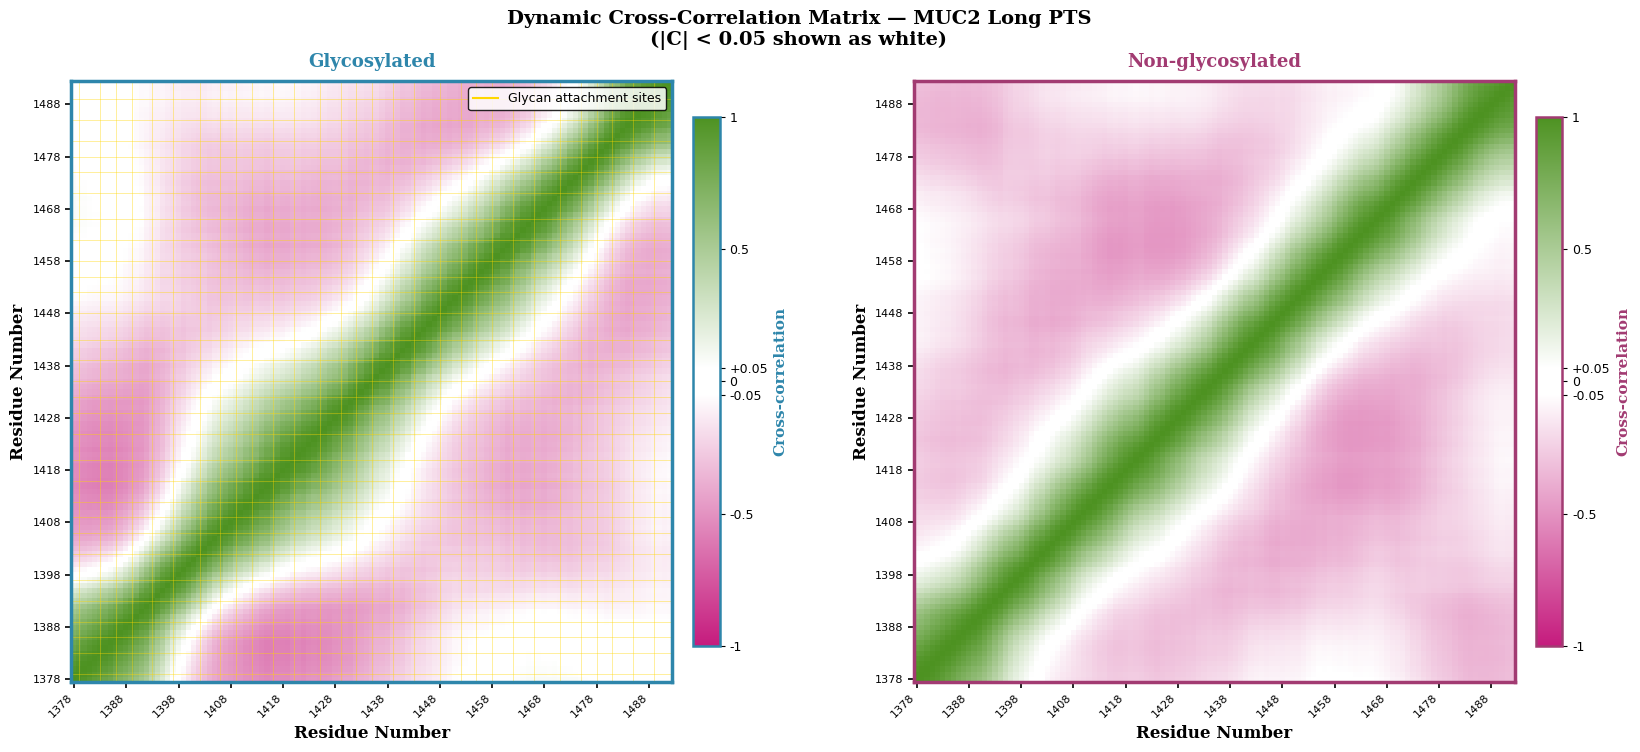

Saved: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_individual.png


In [4]:
def mark_glycan_sites(ax, idx_list, color="gold"):
    for idx in idx_list:
        ax.axvline(idx, color=color, linewidth=0.6, alpha=0.45, zorder=2)
        ax.axhline(idx, color=color, linewidth=0.6, alpha=0.45, zorder=2)

tick_step = 10
tick_pos  = np.arange(0, N_RES, tick_step)
tick_labs = [str(res_nums[i]) for i in tick_pos]

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), dpi=100)
fig.set_facecolor("white")

for ax, mat, title, sys_color, show_glycans in [
    (axes[0], dccm_gly, "Glycosylated",    CLR_GLY, True),
    (axes[1], dccm_nog, "Non-glycosylated", CLR_NOG, False),
]:
    # Use original data — white band is baked into cmap_ind
    im = ax.imshow(mat, cmap=cmap_ind, vmin=-1, vmax=1,
                   origin="lower", aspect="equal")

    if show_glycans:
        mark_glycan_sites(ax, glycan_idx)

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03, shrink=0.88)
    cbar.set_label("Cross-correlation", fontsize=11,
                   fontname="DejaVu Serif", fontweight="bold", color=sys_color)
    cbar.ax.tick_params(labelsize=9)
    cbar.set_ticks([-1, -0.5, -THRESHOLD, 0, THRESHOLD, 0.5, 1])
    cbar.set_ticklabels(["-1", "-0.5", f"-{THRESHOLD}", "0",
                         f"+{THRESHOLD}", "0.5", "1"])
    cbar.outline.set_edgecolor(sys_color)
    cbar.outline.set_linewidth(1.8)

    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_labs, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(tick_labs, fontsize=8)
    ax.set_xlabel("Residue Number", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=13, fontname="DejaVu Serif",
                 fontweight="bold", color=sys_color, pad=10)
    ax.set_facecolor("white")
    ax.tick_params(length=4, width=1.2, direction="out")
    for spine in ax.spines.values():
        spine.set_edgecolor(sys_color)
        spine.set_linewidth(2.5)

    if show_glycans:
        from matplotlib.lines import Line2D
        ax.legend(handles=[Line2D([0], [0], color="gold", linewidth=1.5,
                                  label="Glycan attachment sites")],
                  fontsize=9, loc="upper right", framealpha=0.85,
                  edgecolor="black")

fig.suptitle(f"Dynamic Cross-Correlation Matrix — MUC2 Long PTS\n"
             f"(|C| < {THRESHOLD} shown as white)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
out = os.path.join(output_dir, "dccm_individual.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 2 — Difference Map (Glycosylated − Non-glycosylated)

Positive (blue) = glycosylation *increased* correlated motion between that residue pair.  
Negative (red) = glycosylation *decreased* correlation (or introduced anti-correlation).

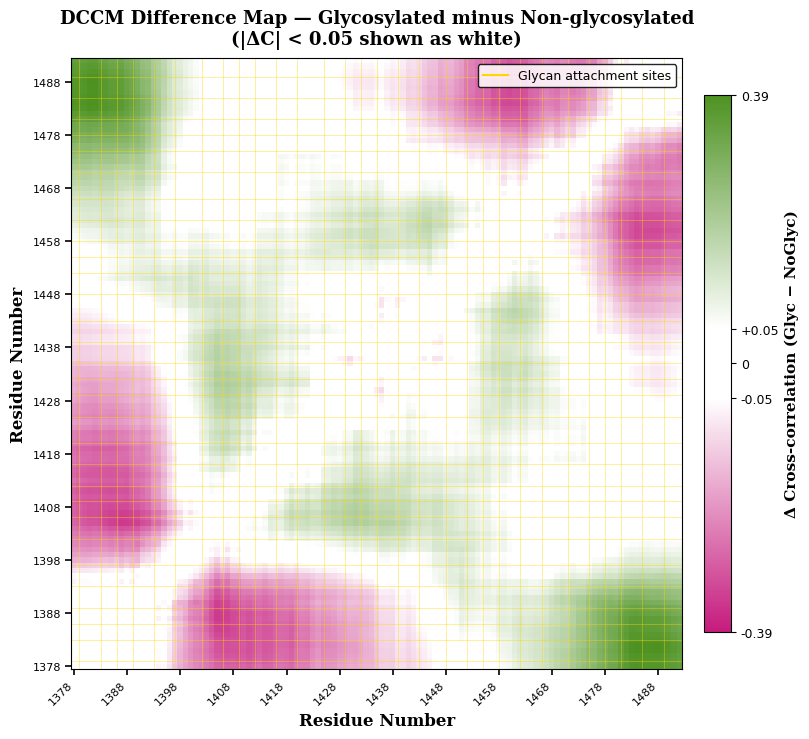

Saved: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_difference.png


In [5]:
fig, ax = plt.subplots(figsize=(8.5, 7.5), dpi=100)
fig.set_facecolor("white")

im = ax.imshow(dccm_diff, cmap=cmap_diff_mg,
               vmin=-vlim, vmax=vlim,
               origin="lower", aspect="equal")

mark_glycan_sites(ax, glycan_idx, color="gold")

cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03, shrink=0.88)
cbar.set_label("Δ Cross-correlation (Glyc − NoGlyc)",
               fontsize=11, fontname="DejaVu Serif", fontweight="bold")
cbar.ax.tick_params(labelsize=9)
cbar.set_ticks([-vlim, -THRESHOLD, 0, THRESHOLD, vlim])
cbar.set_ticklabels([f"{-vlim:.2f}", f"-{THRESHOLD}", "0",
                     f"+{THRESHOLD}", f"{vlim:.2f}"])

ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_labs, rotation=45, ha="right", fontsize=8)
ax.set_yticks(tick_pos)
ax.set_yticklabels(tick_labs, fontsize=8)
ax.set_xlabel("Residue Number", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Residue Number", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title(f"DCCM Difference Map — Glycosylated minus Non-glycosylated\n"
             f"(|ΔC| < {THRESHOLD} shown as white)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.set_facecolor("white")
ax.tick_params(length=4, width=1.2, direction="out")

from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], color="gold", linewidth=1.5,
                          label="Glycan attachment sites")],
          fontsize=9, loc="upper right", framealpha=0.85, edgecolor="black")

plt.tight_layout()
out = os.path.join(output_dir, "dccm_difference.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 3 — Mean Cross-Correlation per Residue

For each residue i, compute the mean |C(i,j)| over all j ≠ i.
Higher values = that residue is strongly correlated (in any direction) with the rest of the chain.

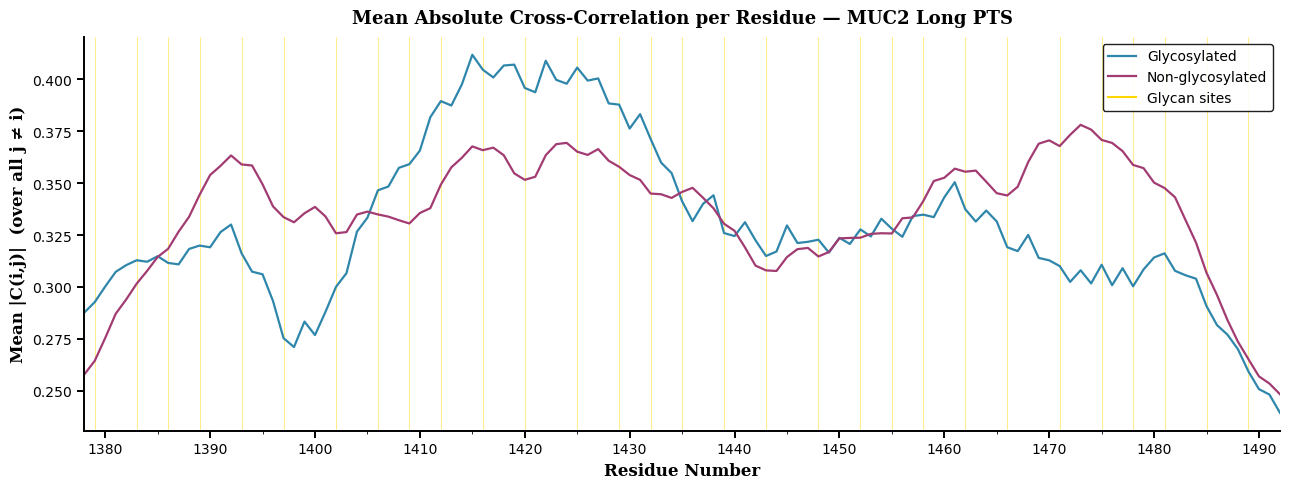

Saved: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_mean_abs_corr.png


In [6]:
# Mean absolute correlation per residue (excluding self)
def mean_abs_corr(mat):
    n = mat.shape[0]
    result = np.zeros(n)
    for i in range(n):
        off_diag = np.concatenate([mat[i, :i], mat[i, i+1:]])
        result[i] = np.mean(np.abs(off_diag))
    return result

mac_gly = mean_abs_corr(dccm_gly)
mac_nog = mean_abs_corr(dccm_nog)

fig, ax = plt.subplots(figsize=(13, 5), dpi=100)
fig.set_facecolor("white")

ax.plot(res_nums, mac_gly, color=CLR_GLY, linewidth=1.6, label="Glycosylated")
ax.plot(res_nums, mac_nog, color=CLR_NOG, linewidth=1.6, label="Non-glycosylated")

# Glycan site vertical lines
for idx in glycan_idx:
    ax.axvline(res_nums[idx], color="gold", linewidth=0.6, alpha=0.55, zorder=0)

# One label for all glycan lines
from matplotlib.lines import Line2D
extra = Line2D([0], [0], color="gold", linewidth=1.5,
               label="Glycan sites (glycosylated)")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles + [extra], labels=labels + ["Glycan sites"],
          fontsize=10, framealpha=0.88, edgecolor="black")

ax.set_xlabel("Residue Number", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Mean |C(i,j)|  (over all j ≠ i)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Mean Absolute Cross-Correlation per Residue — MUC2 Long PTS",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.set_xlim(res_nums[0], res_nums[-1])
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.4)
ax.spines["bottom"].set_linewidth(1.4)
ax.tick_params(labelsize=10, length=5, width=1.4, direction="out")
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(5))

plt.tight_layout()
out = os.path.join(output_dir, "dccm_mean_abs_corr.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 4 — Comparison Side-by-Side (Shared Scale)

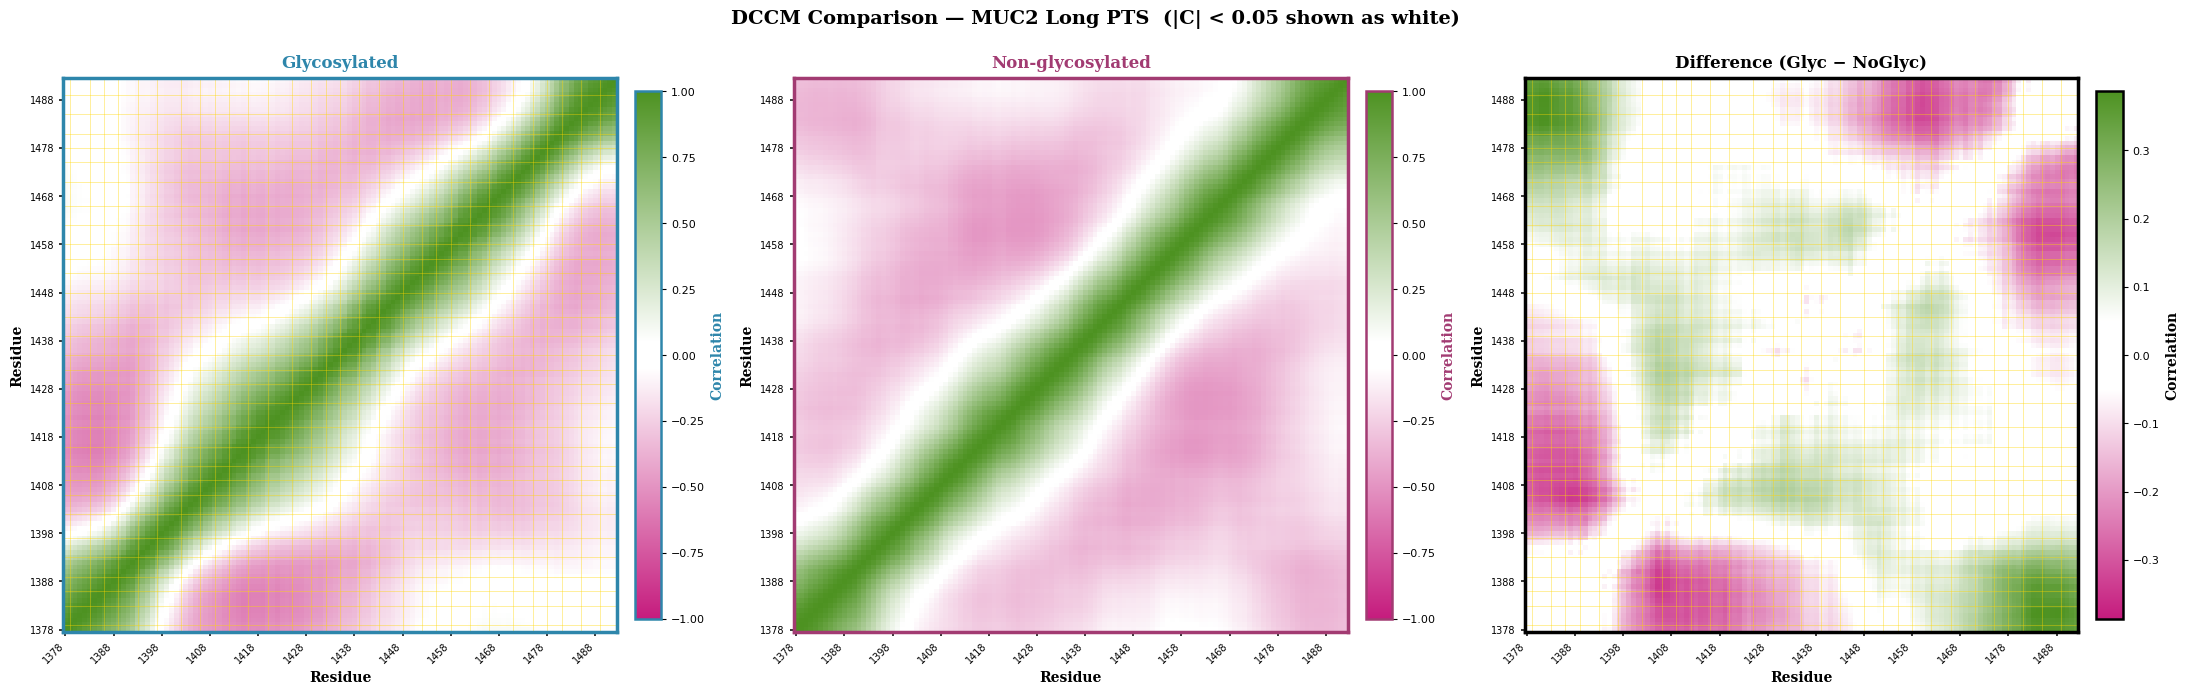

Saved: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_comparison_3panel.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7), dpi=100,
                         gridspec_kw={"width_ratios": [1, 1, 1]})
fig.set_facecolor("white")

panels = [
    (axes[0], dccm_gly,  "Glycosylated",             CLR_GLY, True,  cmap_ind,     -1,    1),
    (axes[1], dccm_nog,  "Non-glycosylated",          CLR_NOG, False, cmap_ind,     -1,    1),
    (axes[2], dccm_diff, "Difference (Glyc − NoGlyc)","black", True,  cmap_diff_mg, -vlim, vlim),
]

for ax, mat, title, color, show_g, cmap, vlo, vhi in panels:
    im = ax.imshow(mat, cmap=cmap, vmin=vlo, vmax=vhi,
                   origin="lower", aspect="equal")
    if show_g:
        mark_glycan_sites(ax, glycan_idx)

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03, shrink=0.85)
    cbar.set_label("Correlation", fontsize=10, fontname="DejaVu Serif",
                   fontweight="bold", color=color)
    cbar.ax.tick_params(labelsize=8)
    cbar.outline.set_edgecolor(color)
    cbar.outline.set_linewidth(1.8)

    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_labs, rotation=45, ha="right", fontsize=7)
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(tick_labs, fontsize=7)
    ax.set_xlabel("Residue", fontsize=10, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Residue", fontsize=10, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=12, fontname="DejaVu Serif",
                 fontweight="bold", color=color, pad=8)
    ax.tick_params(length=3, width=1.1, direction="out")
    for spine in ax.spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(2.5)

fig.suptitle(f"DCCM Comparison — MUC2 Long PTS  (|C| < {THRESHOLD} shown as white)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
out = os.path.join(output_dir, "dccm_comparison_3panel.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

Ext. Glycosylated shape: (115, 115)  min=-0.717  max=1.000


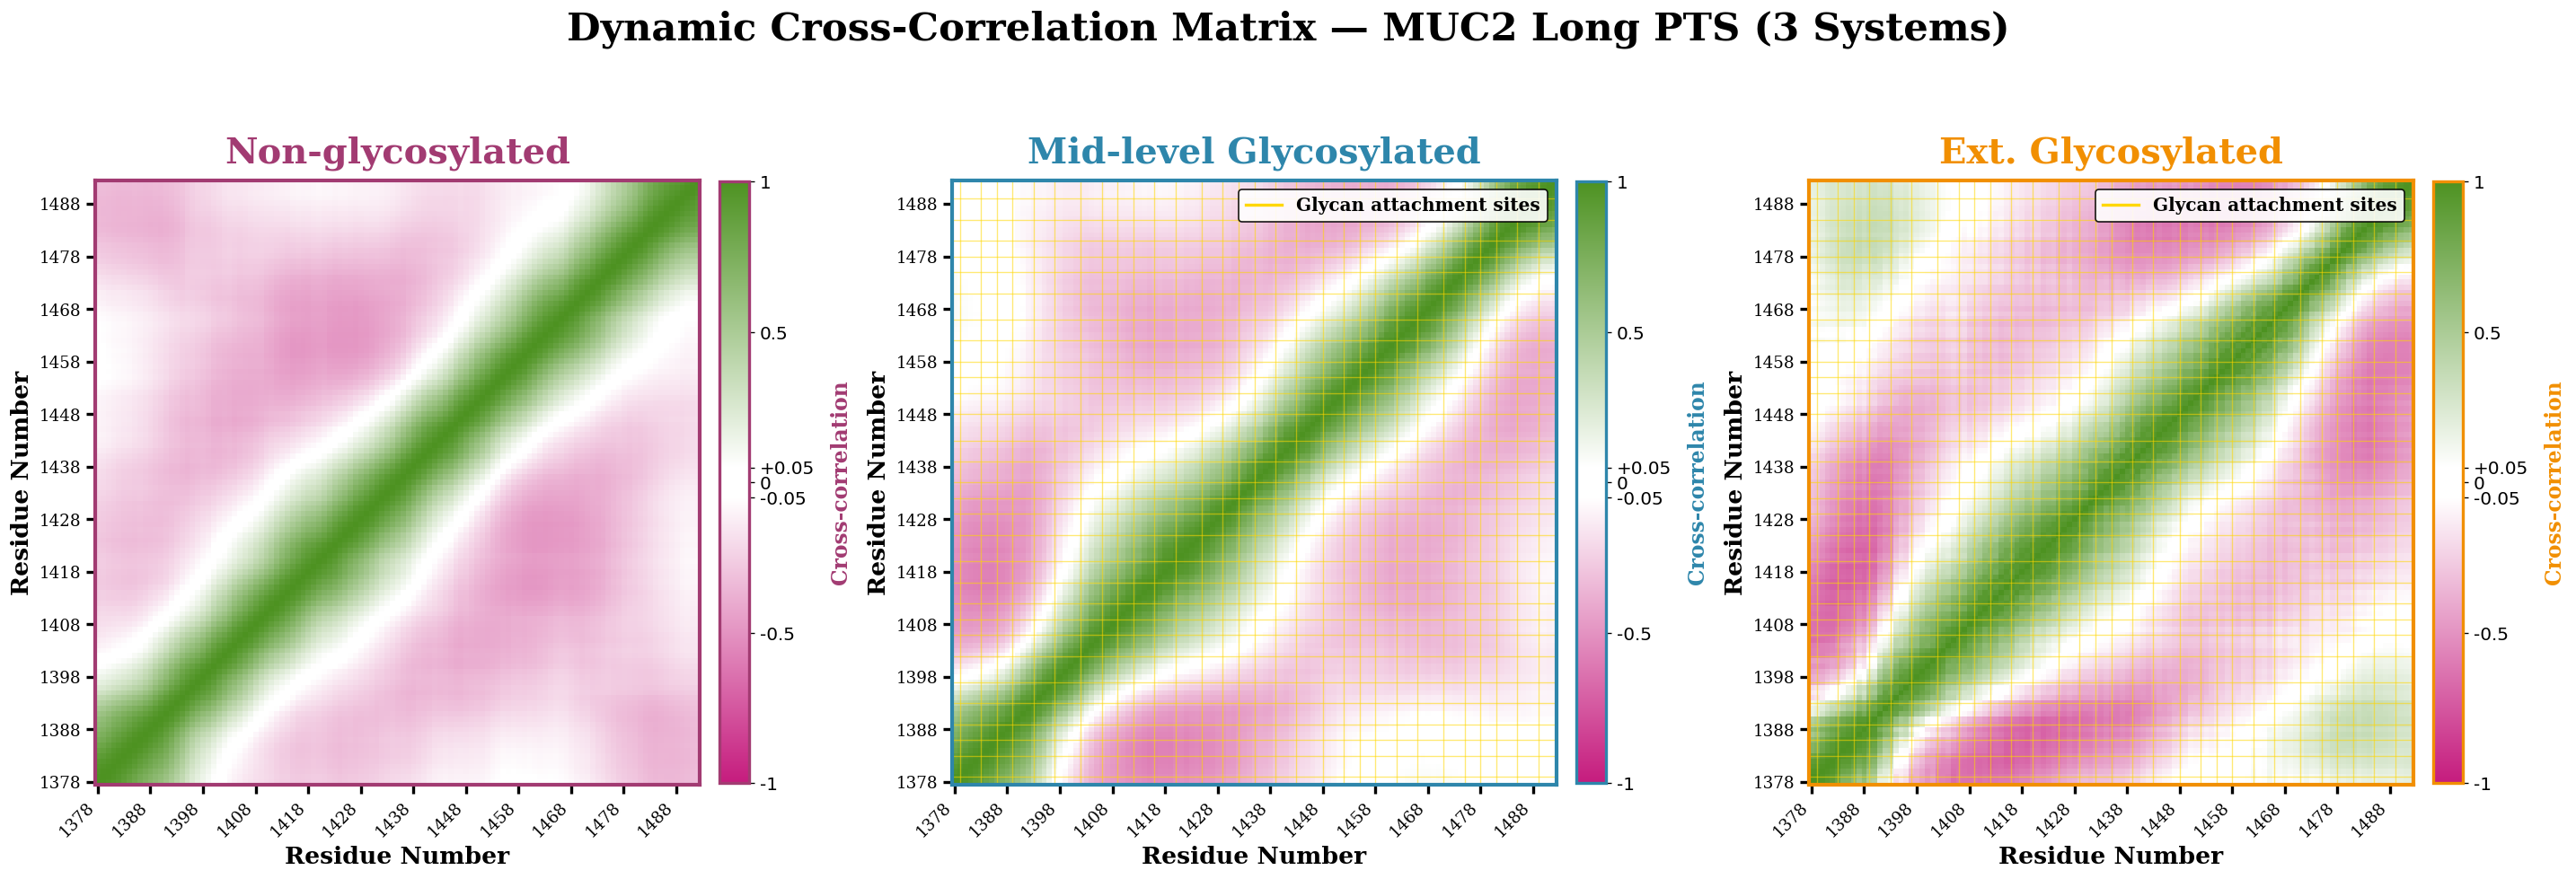

Saved: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_3sys.png


In [8]:
import matplotlib.cm as mpl_cm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

# ── Load ext glycans DCCM ─────────────────────────────────────────────────────
CLR_EXT  = "#F18F01"
dccm_ext = np.loadtxt(base + "muc2_dccm_extraglyc.txt")
print(f"Ext. Glycosylated shape: {dccm_ext.shape}  "
      f"min={dccm_ext.min():.3f}  max={dccm_ext.max():.3f}")

# ── Colormap — same template as fig1 (magenta-white-green) ───────────────────
THRESHOLD = 0.05
lo_pos = (1 - THRESHOLD) / 2   # 0.475
hi_pos = (1 + THRESHOLD) / 2   # 0.525
cmap_3sys = LinearSegmentedColormap.from_list("MagWhtGrn_3sys", [
    (0.0,    "#C51B7D"),
    (lo_pos, "white"),
    (hi_pos, "white"),
    (1.0,    "#4D9221"),
], N=2048)

tick_step = 10
tick_pos  = np.arange(0, N_RES, tick_step)
tick_labs = [str(res_nums[i]) for i in tick_pos]

# Canonical order: Non-glycosylated -> Mid-level Glycosylated -> Ext. Glycosylated
panels = [
    (dccm_nog, "Non-glycosylated",       CLR_NOG, False),
    (dccm_gly, "Mid-level Glycosylated", CLR_GLY, True),
    (dccm_ext, "Ext. Glycosylated",      CLR_EXT, True),
]

fig, axes = plt.subplots(1, 3, figsize=(24, 8), dpi=120,
                         gridspec_kw={"width_ratios": [1, 1, 1]})
fig.set_facecolor("white")

for ax, (mat, title, sys_color, show_glycans) in zip(axes, panels):
    im = ax.imshow(mat, cmap=cmap_3sys, vmin=-1, vmax=1,
                   origin="lower", aspect="equal")

    if show_glycans:
        for idx in glycan_idx:
            ax.axvline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
            ax.axhline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03, shrink=0.88)
    cbar.set_label("Cross-correlation", fontsize=14,
                   fontname="DejaVu Serif", fontweight="bold",
                   color=sys_color, labelpad=10)
    cbar.ax.tick_params(labelsize=12)
    cbar.set_ticks([-1, -0.5, -THRESHOLD, 0, THRESHOLD, 0.5, 1])
    cbar.set_ticklabels(["-1", "-0.5", f"-{THRESHOLD}", "0",
                         f"+{THRESHOLD}", "0.5", "1"])
    cbar.outline.set_edgecolor(sys_color)
    cbar.outline.set_linewidth(2.0)

    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_labs, rotation=45, ha="right",
                       fontsize=11, fontname="DejaVu Serif")
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(tick_labs, fontsize=11, fontname="DejaVu Serif")
    ax.set_xlabel("Residue Number", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=24, fontname="DejaVu Serif",
                 fontweight="bold", color=sys_color, pad=12)
    ax.tick_params(length=6, width=2.0, direction="out")
    for spine in ax.spines.values():
        spine.set_edgecolor(sys_color)
        spine.set_linewidth(2.5)

    if show_glycans:
        ax.legend(
            handles=[Line2D([0], [0], color="gold", linewidth=2.0,
                            label="Glycan attachment sites")],
            fontsize=12, loc="upper right", framealpha=0.90,
            edgecolor="black",
            prop={"family": "DejaVu Serif", "size": 12, "weight": "bold"},
        )

fig.suptitle(
    "Dynamic Cross-Correlation Matrix \u2014 MUC2 Long PTS (3 Systems)",
    fontsize=26, fontname="DejaVu Serif", fontweight="bold", y=1.03)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


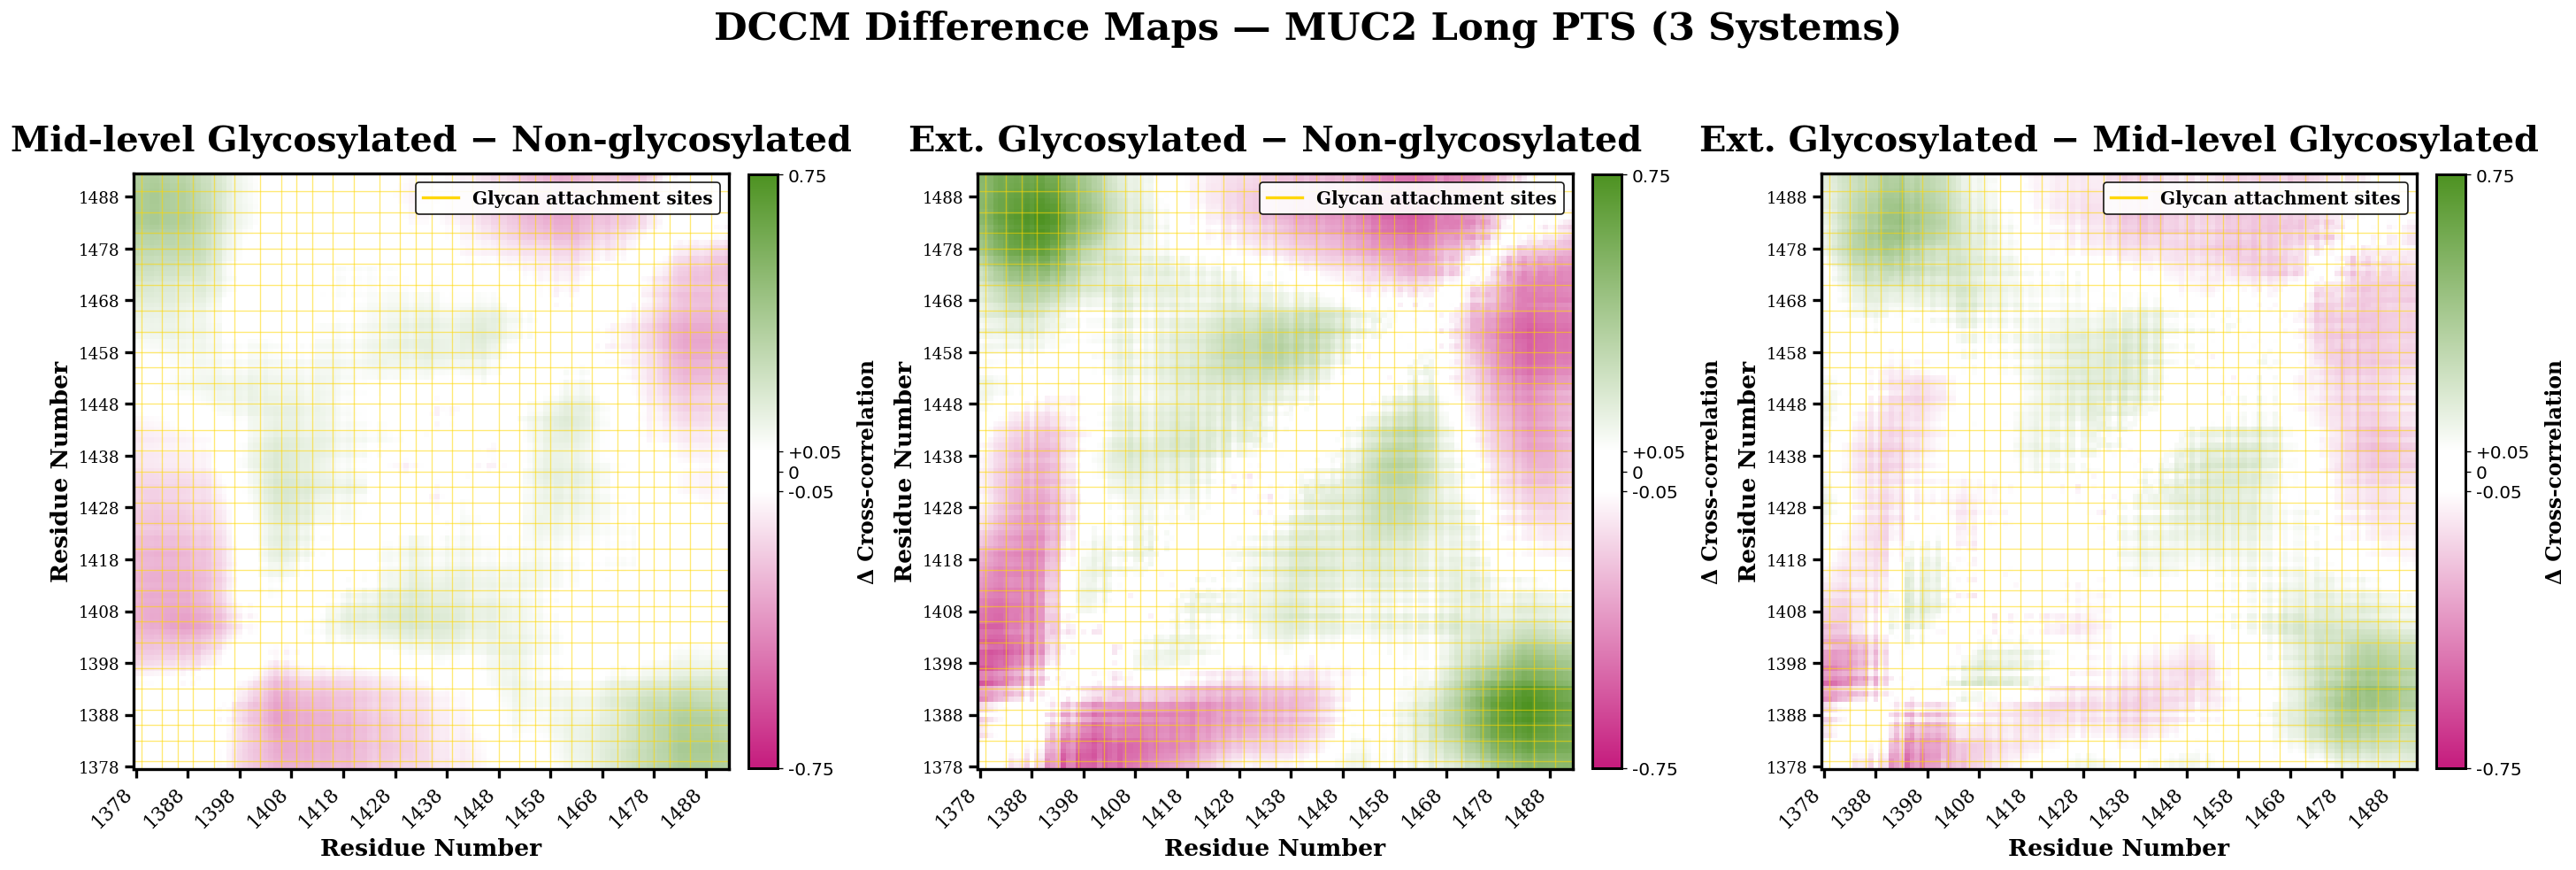

Saved combined: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_diff_3sys.png


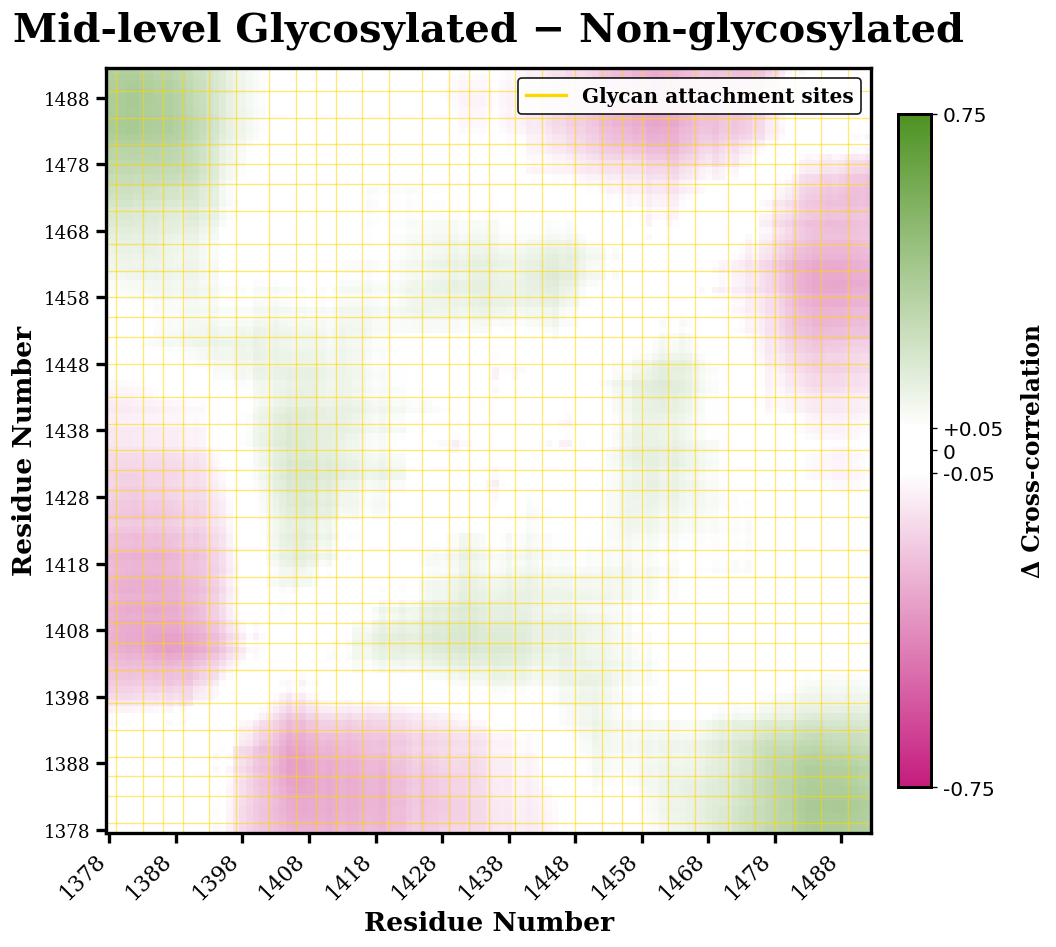

Saved: dccm_diff_gly_nog.png


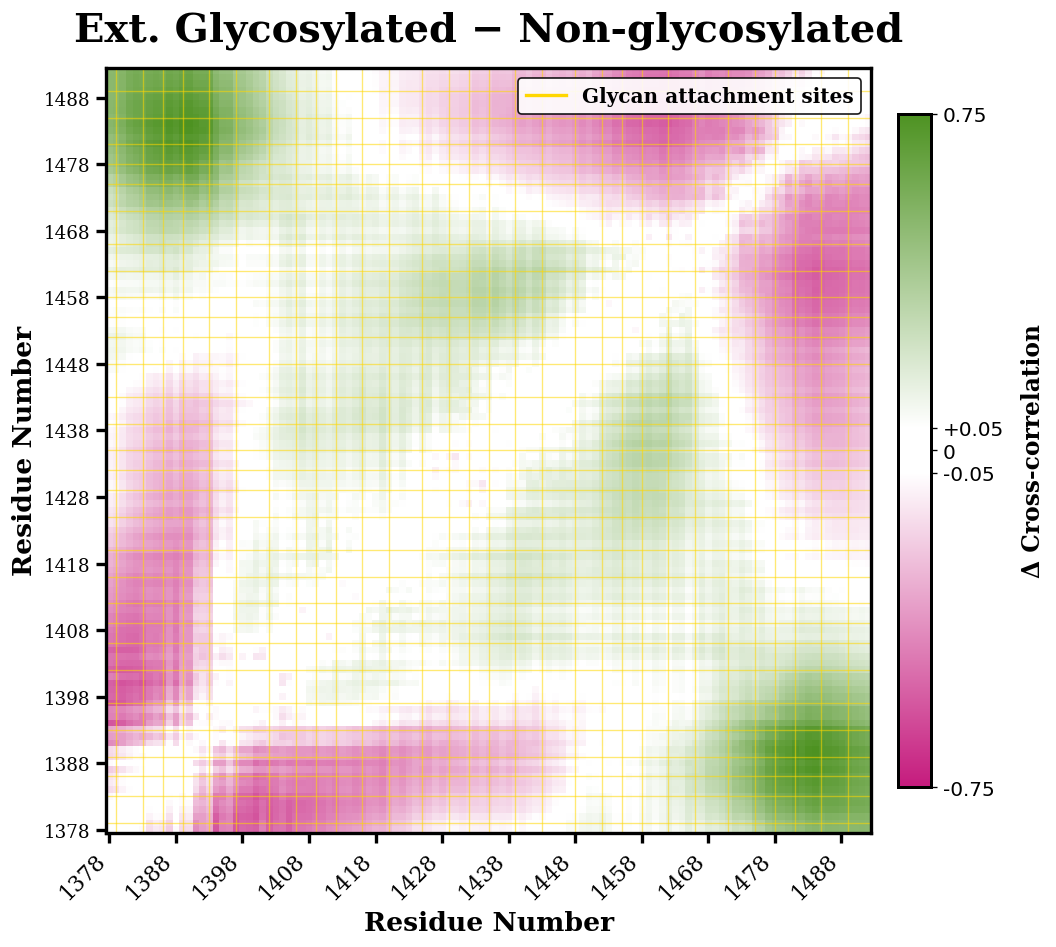

Saved: dccm_diff_ext_nog.png


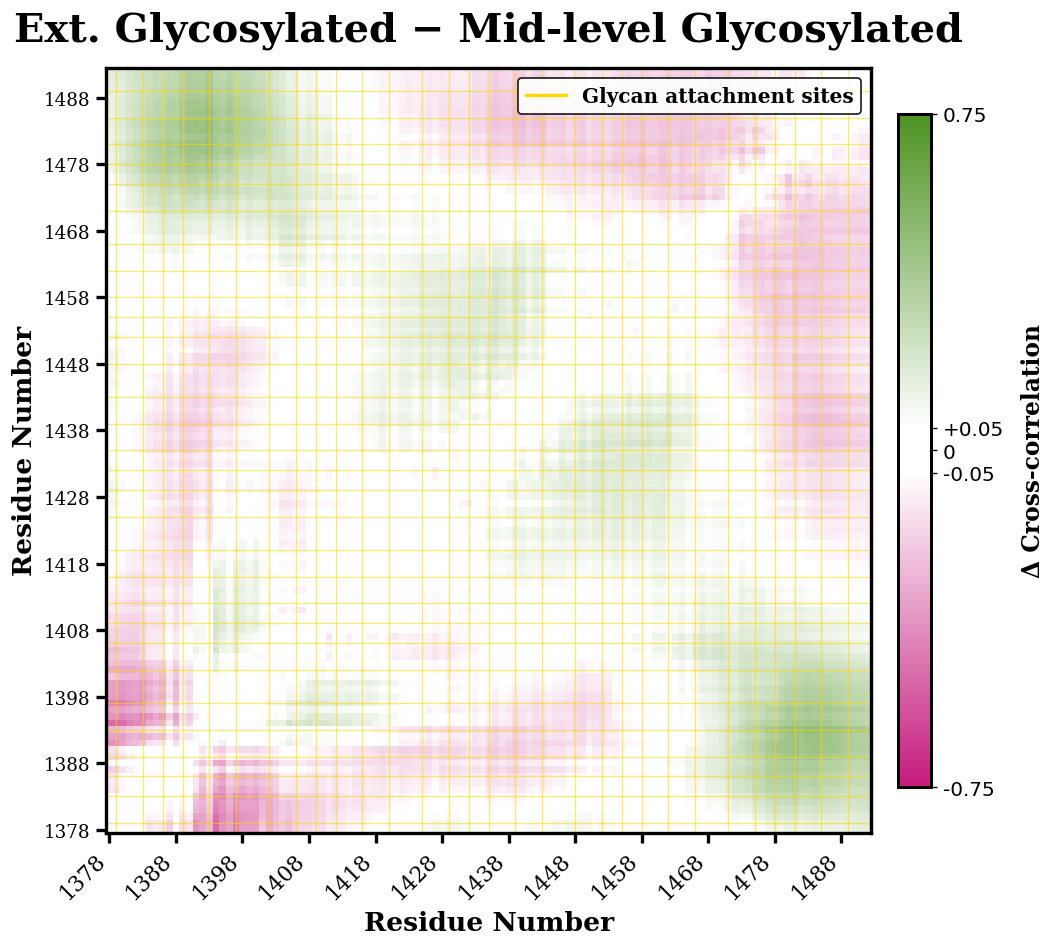

Saved: dccm_diff_ext_gly.png


In [9]:
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap

# ── 3 Difference Maps ─────────────────────────────────────────────────────────
# 1. Mid-level Glycosylated − Non-glycosylated
# 2. Ext. Glycosylated − Non-glycosylated
# 3. Ext. Glycosylated − Mid-level Glycosylated

diff_panels = [
    (dccm_gly - dccm_nog,
     "Mid-level Glycosylated \u2212 Non-glycosylated",
     "dccm_diff_gly_nog.png"),
    (dccm_ext - dccm_nog,
     "Ext. Glycosylated \u2212 Non-glycosylated",
     "dccm_diff_ext_nog.png"),
    (dccm_ext - dccm_gly,
     "Ext. Glycosylated \u2212 Mid-level Glycosylated",
     "dccm_diff_ext_gly.png"),
]

THRESHOLD = 0.05
tick_step = 10
tick_pos  = np.arange(0, N_RES, tick_step)
tick_labs = [str(res_nums[i]) for i in tick_pos]

# Shared vlim across all three differences for direct comparability
vlim_all = max(np.abs(d).max() for d, *_ in diff_panels)

fig, axes = plt.subplots(1, 3, figsize=(24, 8), dpi=120)
fig.set_facecolor("white")

for ax, (diff_mat, title, fname) in zip(axes, diff_panels):
    vlim = vlim_all
    lo_n = (vlim - THRESHOLD) / (2 * vlim)
    hi_n = (vlim + THRESHOLD) / (2 * vlim)
    cmap_diff = LinearSegmentedColormap.from_list("MagWhtGrn_diff", [
        (0.0,   "#C51B7D"),
        (lo_n,  "white"),
        (hi_n,  "white"),
        (1.0,   "#4D9221"),
    ], N=2048)

    im = ax.imshow(diff_mat, cmap=cmap_diff, vmin=-vlim, vmax=vlim,
                   origin="lower", aspect="equal")

    for idx in glycan_idx:
        ax.axvline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
        ax.axhline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03, shrink=0.88)
    cbar.set_label("\u0394 Cross-correlation", fontsize=14,
                   fontname="DejaVu Serif", fontweight="bold", labelpad=10)
    cbar.ax.tick_params(labelsize=12)
    cbar.set_ticks([-vlim, -THRESHOLD, 0, THRESHOLD, vlim])
    cbar.set_ticklabels([f"{-vlim:.2f}", f"-{THRESHOLD}", "0",
                         f"+{THRESHOLD}", f"{vlim:.2f}"])
    cbar.outline.set_linewidth(1.8)

    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_labs, rotation=45, ha="right",
                       fontsize=13, fontname="DejaVu Serif")
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(tick_labs, fontsize=11, fontname="DejaVu Serif")
    ax.set_xlabel("Residue Number", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title,
                 fontsize=24, fontname="DejaVu Serif", fontweight="bold", pad=16)
    ax.tick_params(length=6, width=2.0, direction="out")
    for spine in ax.spines.values():
        spine.set_linewidth(2.0)

    ax.legend(
        handles=[Line2D([0], [0], color="gold", linewidth=2.0,
                        label="Glycan attachment sites")],
        fontsize=12, loc="upper right", framealpha=0.90, edgecolor="black",
        prop={"family": "DejaVu Serif", "size": 12, "weight": "bold"},
    )

fig.suptitle(
    "DCCM Difference Maps \u2014 MUC2 Long PTS (3 Systems)",
    fontsize=26, fontname="DejaVu Serif", fontweight="bold", y=1.03)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_diff_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved combined: {out}")

# Also save each panel individually
for diff_mat, title, fname in diff_panels:
    vlim = vlim_all
    lo_n = (vlim - THRESHOLD) / (2 * vlim)
    hi_n = (vlim + THRESHOLD) / (2 * vlim)
    cmap_diff = LinearSegmentedColormap.from_list("MagWhtGrn_diff", [
        (0.0,   "#C51B7D"),
        (lo_n,  "white"),
        (hi_n,  "white"),
        (1.0,   "#4D9221"),
    ], N=2048)

    fig2, ax2 = plt.subplots(figsize=(9, 8), dpi=120)
    fig2.set_facecolor("white")

    im2 = ax2.imshow(diff_mat, cmap=cmap_diff, vmin=-vlim, vmax=vlim,
                     origin="lower", aspect="equal")
    for idx in glycan_idx:
        ax2.axvline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
        ax2.axhline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)

    cbar2 = plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.03, shrink=0.88)
    cbar2.set_label("\u0394 Cross-correlation", fontsize=14,
                    fontname="DejaVu Serif", fontweight="bold", labelpad=10)
    cbar2.ax.tick_params(labelsize=12)
    cbar2.set_ticks([-vlim, -THRESHOLD, 0, THRESHOLD, vlim])
    cbar2.set_ticklabels([f"{-vlim:.2f}", f"-{THRESHOLD}", "0",
                          f"+{THRESHOLD}", f"{vlim:.2f}"])
    cbar2.outline.set_linewidth(1.8)

    ax2.set_xticks(tick_pos)
    ax2.set_xticklabels(tick_labs, rotation=45, ha="right",
                        fontsize=13, fontname="DejaVu Serif")
    ax2.set_yticks(tick_pos)
    ax2.set_yticklabels(tick_labs, fontsize=11, fontname="DejaVu Serif")
    ax2.set_xlabel("Residue Number", fontsize=16,
                   fontname="DejaVu Serif", fontweight="bold")
    ax2.set_ylabel("Residue Number", fontsize=16,
                   fontname="DejaVu Serif", fontweight="bold")
    ax2.set_title(title,
                  fontsize=24, fontname="DejaVu Serif", fontweight="bold", pad=16)
    ax2.tick_params(length=6, width=2.0, direction="out")
    for spine in ax2.spines.values():
        spine.set_linewidth(2.0)
    ax2.legend(
        handles=[Line2D([0], [0], color="gold", linewidth=2.0,
                        label="Glycan attachment sites")],
        fontsize=12, loc="upper right", framealpha=0.90, edgecolor="black",
        prop={"family": "DejaVu Serif", "size": 12, "weight": "bold"},
    )
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, fname), dpi=300,
                bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {fname}")


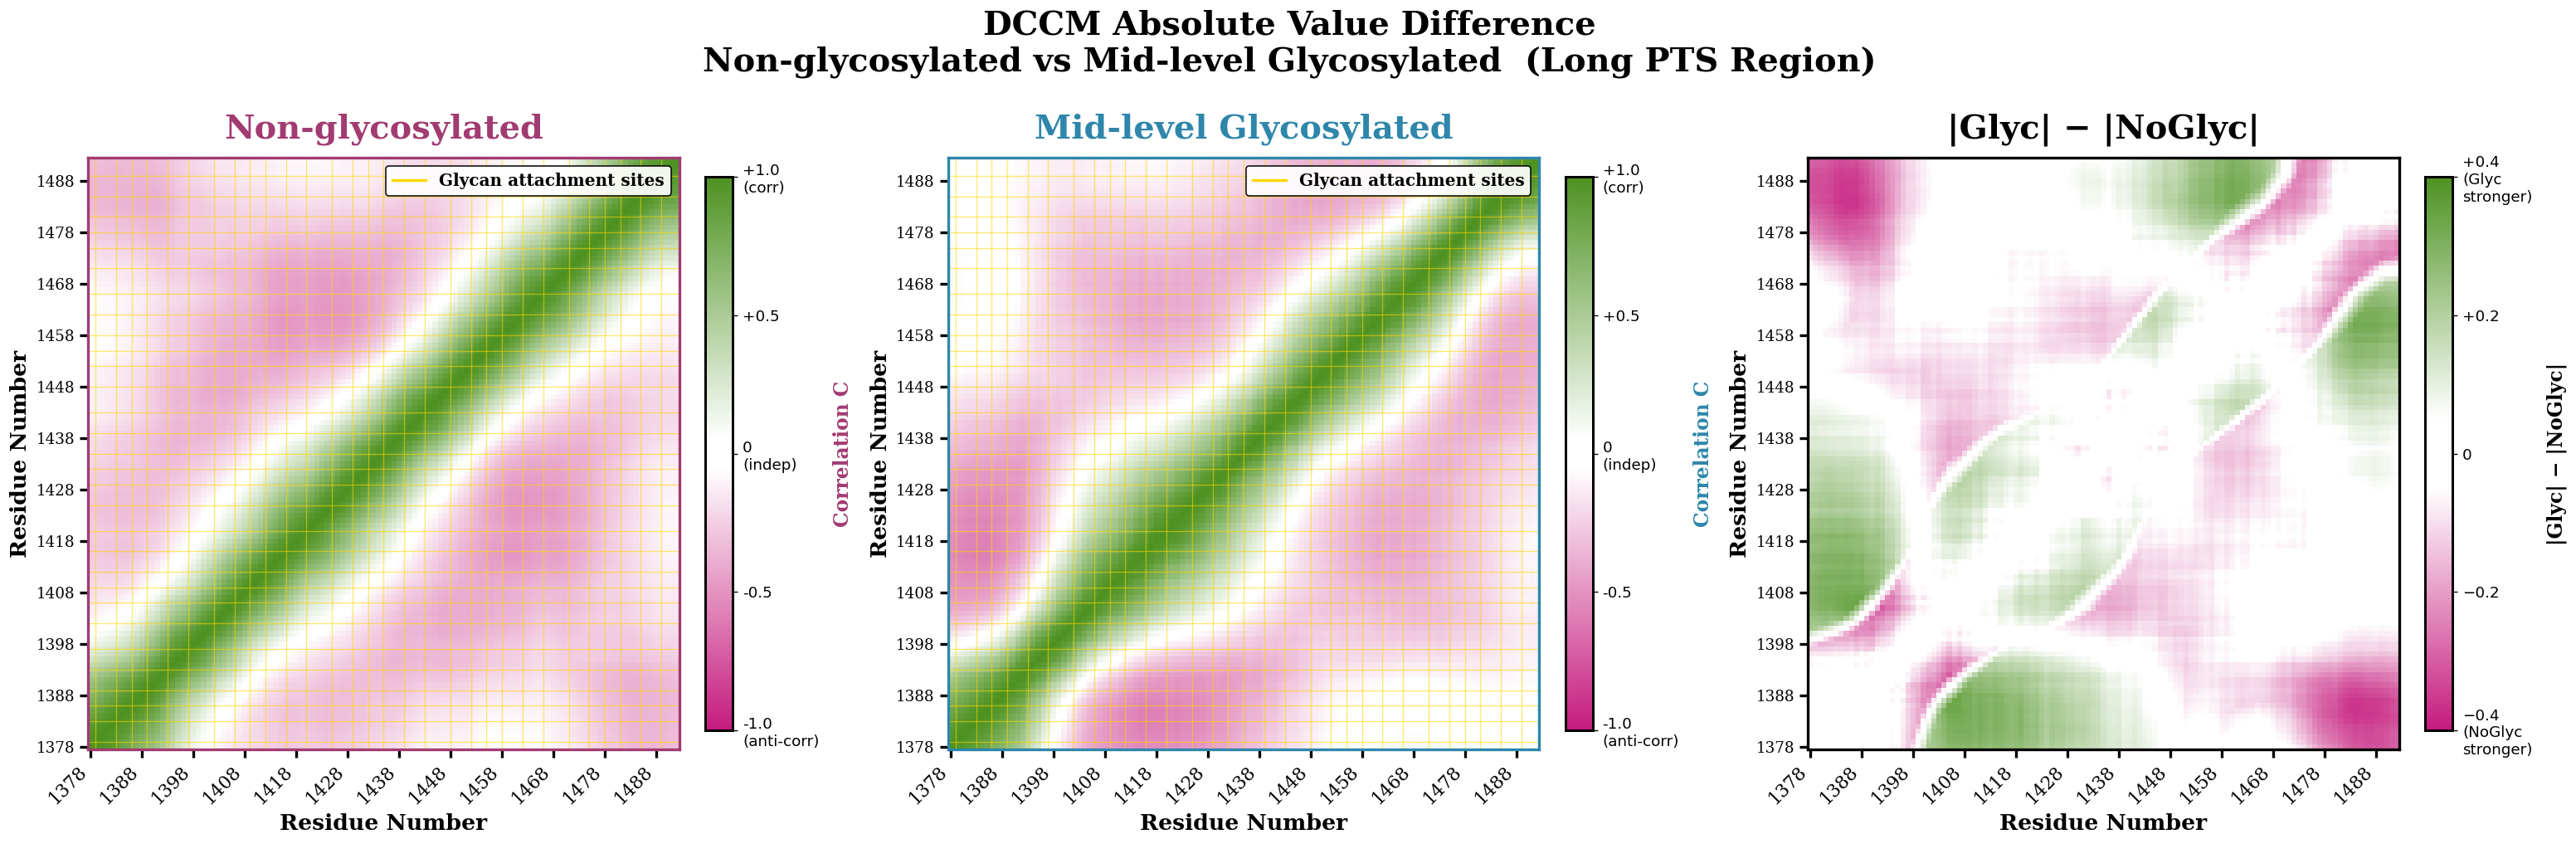

Saved: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_abs_diff_gly_nog.png


In [10]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

THRESHOLD = 0.05
tick_step = 10
tick_pos  = np.arange(0, N_RES, tick_step)
tick_labs = [str(res_nums[i]) for i in tick_pos]

abs_diff_gn = np.abs(dccm_gly) - np.abs(dccm_nog)

lo_pos = (1 - THRESHOLD) / 2
hi_pos = (1 + THRESHOLD) / 2
cmap_dccm = LinearSegmentedColormap.from_list("MWG", [
    (0.0, "#C51B7D"), (lo_pos, "white"), (hi_pos, "white"), (1.0, "#4D9221")
], N=2048)

vlim_abs = 0.40
lo_abs = (vlim_abs - THRESHOLD) / (2 * vlim_abs)
hi_abs = (vlim_abs + THRESHOLD) / (2 * vlim_abs)
cmap_abs = LinearSegmentedColormap.from_list("MWG_abs", [
    (0.0, "#C51B7D"), (lo_abs, "white"), (hi_abs, "white"), (1.0, "#4D9221")
], N=2048)

fig, axes = plt.subplots(1, 3, figsize=(26, 8), dpi=120)
fig.set_facecolor("white")

panels = [
    (axes[0], dccm_nog,    "Non-glycosylated",        CLR_NOG, cmap_dccm, -1,        1,
     "Correlation C", [-1,-0.5,0,0.5,1],
     ["-1.0\n(anti-corr)","-0.5","0\n(indep)","+0.5","+1.0\n(corr)"], True),
    (axes[1], dccm_gly,    "Mid-level Glycosylated",  CLR_GLY, cmap_dccm, -1,        1,
     "Correlation C", [-1,-0.5,0,0.5,1],
     ["-1.0\n(anti-corr)","-0.5","0\n(indep)","+0.5","+1.0\n(corr)"], True),
    (axes[2], abs_diff_gn, "|Glyc| \u2212 |NoGlyc|", "black",  cmap_abs, -vlim_abs, vlim_abs,
     "|Glyc| \u2212 |NoGlyc|", [-0.4,-0.2,0,0.2,0.4],
     ["\u22120.4\n(NoGlyc\nstronger)","\u22120.2","0","+0.2","+0.4\n(Glyc\nstronger)"], False),
]

for ax, mat, title, spine_clr, cmap, vmin, vmax, cbar_lbl, cbar_ticks, cbar_tlabels, show_gly in panels:
    im = ax.imshow(mat, cmap=cmap, vmin=vmin, vmax=vmax, origin="lower", aspect="equal")
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, shrink=0.88)
    cbar.set_label(cbar_lbl, fontsize=14, fontname="DejaVu Serif",
                   fontweight="bold", color=spine_clr, labelpad=10)
    cbar.set_ticks(cbar_ticks)
    cbar.ax.set_yticklabels(cbar_tlabels, fontsize=10)
    cbar.ax.tick_params(labelsize=11)
    cbar.outline.set_linewidth(1.8)
    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_labs, rotation=45, ha="right", fontsize=13, fontname="DejaVu Serif")
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(tick_labs, fontsize=11, fontname="DejaVu Serif")
    ax.set_xlabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=24, fontname="DejaVu Serif",
                 fontweight="bold", color=spine_clr, pad=14)
    ax.tick_params(length=6, width=2.0, direction="out")
    for spine in ax.spines.values():
        spine.set_linewidth(2.0); spine.set_edgecolor(spine_clr)
    if show_gly:
        for idx in glycan_idx:
            ax.axvline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
            ax.axhline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
        ax.legend(
            handles=[Line2D([0],[0], color="gold", linewidth=2.0,
                            label="Glycan attachment sites")],
            fontsize=12, loc="upper right",
            prop={"family":"DejaVu Serif","size":12,"weight":"bold"},
            framealpha=0.92, edgecolor="black")

fig.suptitle(
    "DCCM Absolute Value Difference\n"
    "Non-glycosylated vs Mid-level Glycosylated  (Long PTS Region)",
    fontsize=24, fontname="DejaVu Serif", fontweight="bold", y=1.03)
plt.tight_layout()
out_abs = os.path.join(output_dir, "dccm_abs_diff_gly_nog.png")
plt.savefig(out_abs, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out_abs}")


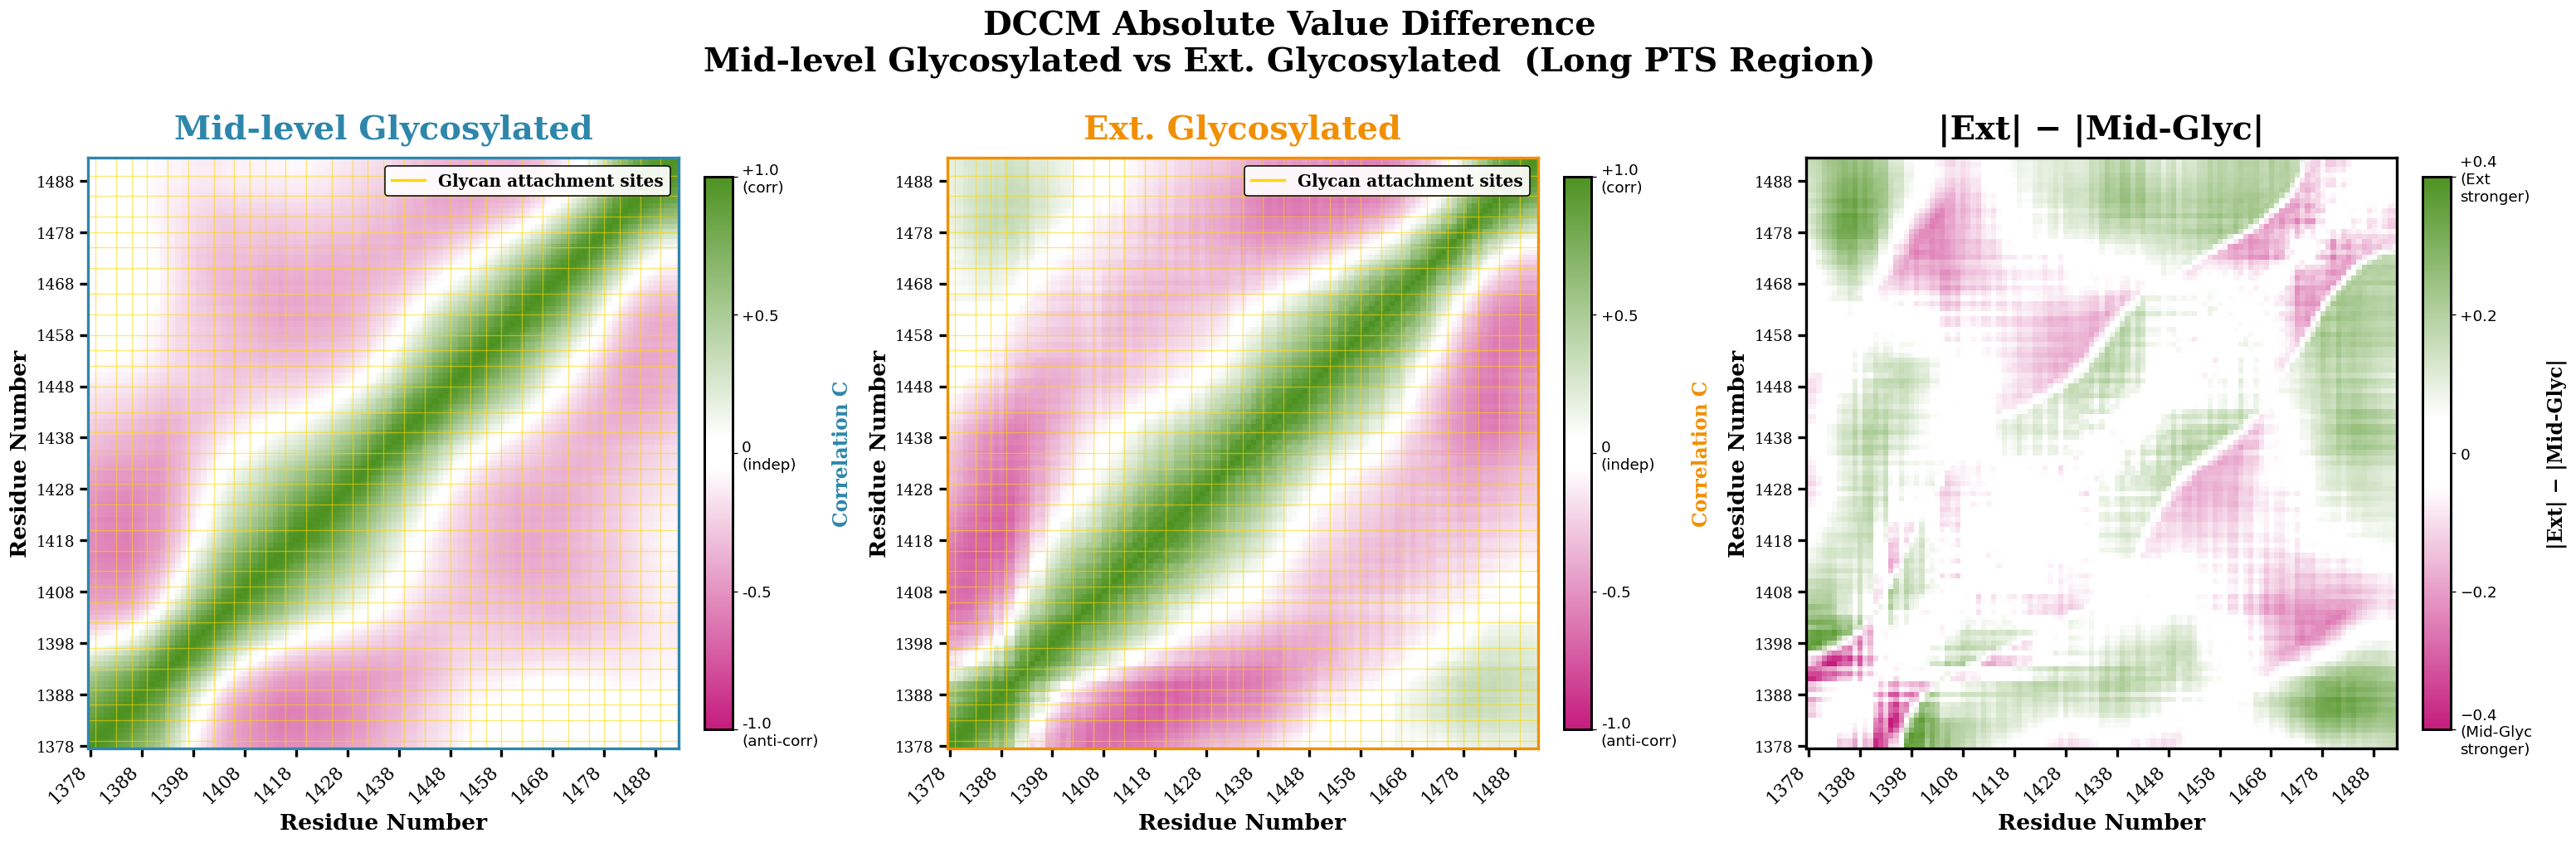

Saved: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_abs_diff_ext_gly.png


In [11]:
abs_diff_eg = np.abs(dccm_ext) - np.abs(dccm_gly)

fig, axes = plt.subplots(1, 3, figsize=(26, 8), dpi=120)
fig.set_facecolor("white")

panels_eg = [
    (axes[0], dccm_gly,    "Mid-level Glycosylated",  CLR_GLY, cmap_dccm, -1,        1,
     "Correlation C", [-1,-0.5,0,0.5,1],
     ["-1.0\n(anti-corr)","-0.5","0\n(indep)","+0.5","+1.0\n(corr)"], True),
    (axes[1], dccm_ext,    "Ext. Glycosylated",        CLR_EXT, cmap_dccm, -1,        1,
     "Correlation C", [-1,-0.5,0,0.5,1],
     ["-1.0\n(anti-corr)","-0.5","0\n(indep)","+0.5","+1.0\n(corr)"], True),
    (axes[2], abs_diff_eg, "|Ext| \u2212 |Mid-Glyc|",  "black",  cmap_abs, -vlim_abs, vlim_abs,
     "|Ext| \u2212 |Mid-Glyc|", [-0.4,-0.2,0,0.2,0.4],
     ["\u22120.4\n(Mid-Glyc\nstronger)","\u22120.2","0","+0.2","+0.4\n(Ext\nstronger)"], False),
]

for ax, mat, title, spine_clr, cmap, vmin, vmax, cbar_lbl, cbar_ticks, cbar_tlabels, show_gly in panels_eg:
    im = ax.imshow(mat, cmap=cmap, vmin=vmin, vmax=vmax, origin="lower", aspect="equal")
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, shrink=0.88)
    cbar.set_label(cbar_lbl, fontsize=14, fontname="DejaVu Serif",
                   fontweight="bold", color=spine_clr, labelpad=10)
    cbar.set_ticks(cbar_ticks)
    cbar.ax.set_yticklabels(cbar_tlabels, fontsize=10)
    cbar.ax.tick_params(labelsize=11)
    cbar.outline.set_linewidth(1.8)
    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_labs, rotation=45, ha="right", fontsize=13, fontname="DejaVu Serif")
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(tick_labs, fontsize=11, fontname="DejaVu Serif")
    ax.set_xlabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=24, fontname="DejaVu Serif",
                 fontweight="bold", color=spine_clr, pad=14)
    ax.tick_params(length=6, width=2.0, direction="out")
    for spine in ax.spines.values():
        spine.set_linewidth(2.0); spine.set_edgecolor(spine_clr)
    if show_gly:
        for idx in glycan_idx:
            ax.axvline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
            ax.axhline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
        ax.legend(
            handles=[Line2D([0],[0], color="gold", linewidth=2.0,
                            label="Glycan attachment sites")],
            fontsize=12, loc="upper right",
            prop={"family":"DejaVu Serif","size":12,"weight":"bold"},
            framealpha=0.92, edgecolor="black")

fig.suptitle(
    "DCCM Absolute Value Difference\n"
    "Mid-level Glycosylated vs Ext. Glycosylated  (Long PTS Region)",
    fontsize=24, fontname="DejaVu Serif", fontweight="bold", y=1.03)
plt.tight_layout()
out_eg = os.path.join(output_dir, "dccm_abs_diff_ext_gly.png")
plt.savefig(out_eg, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out_eg}")


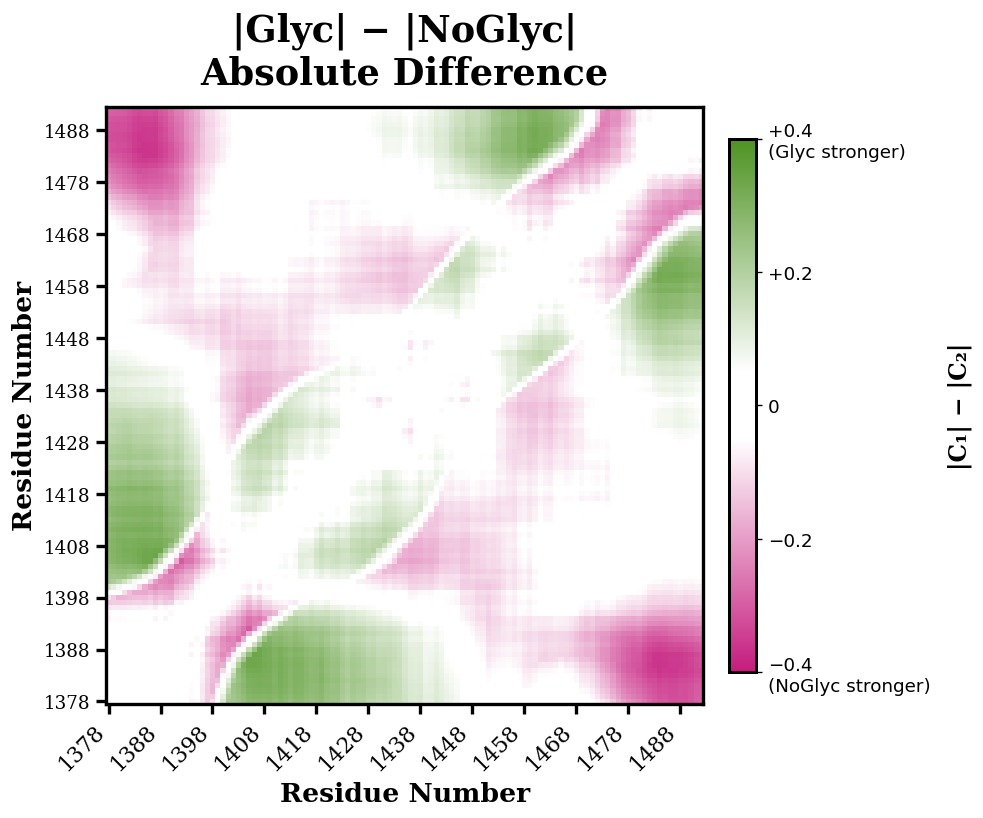

Saved: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_abs_diff_gly_nog_single.png


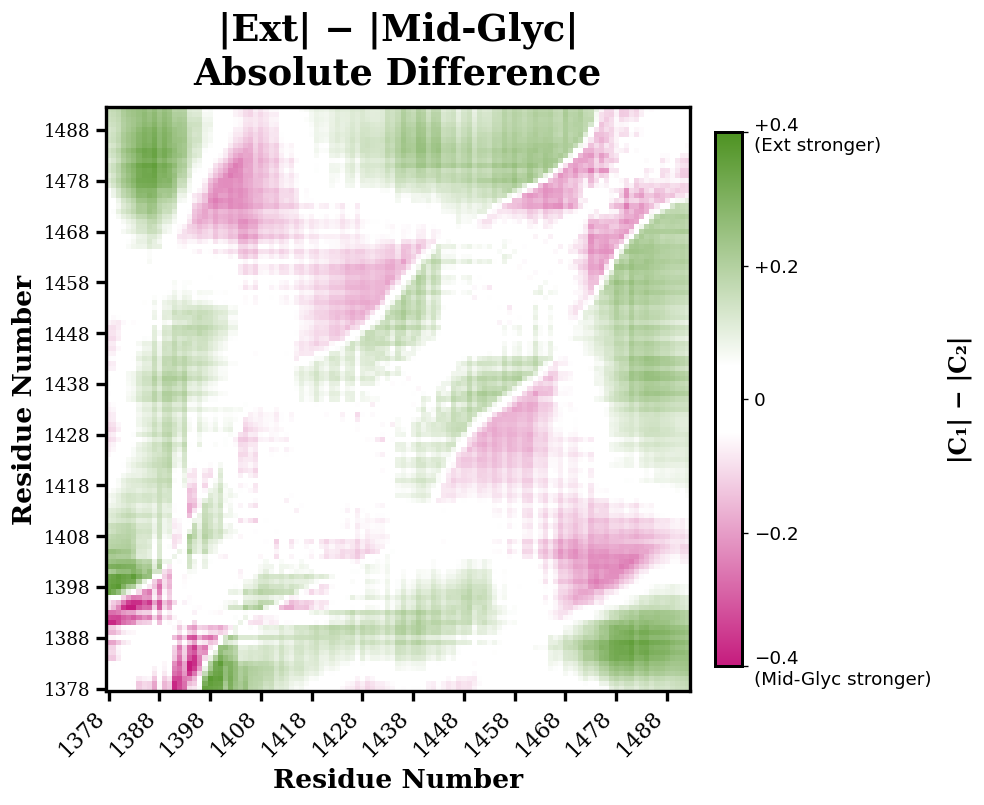

Saved: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_abs_diff_ext_gly_single.png


In [12]:
# Individual absolute difference maps
for abs_mat, fname, title, cbar_neg, cbar_pos in [
    (np.abs(dccm_gly) - np.abs(dccm_nog),
     "dccm_abs_diff_gly_nog_single.png",
     "|Glyc| \u2212 |NoGlyc|\nAbsolute Difference",
     "NoGlyc stronger", "Glyc stronger"),
    (np.abs(dccm_ext) - np.abs(dccm_gly),
     "dccm_abs_diff_ext_gly_single.png",
     "|Ext| \u2212 |Mid-Glyc|\nAbsolute Difference",
     "Mid-Glyc stronger", "Ext stronger"),
]:
    vlim_abs = 0.40
    lo_abs = (vlim_abs - THRESHOLD) / (2 * vlim_abs)
    hi_abs = (vlim_abs + THRESHOLD) / (2 * vlim_abs)
    cmap_abs = LinearSegmentedColormap.from_list("MWG_abs", [
        (0.0, "#C51B7D"), (lo_abs, "white"), (hi_abs, "white"), (1.0, "#4D9221")
    ], N=2048)

    fig, ax = plt.subplots(figsize=(8, 7), dpi=120)
    fig.set_facecolor("white")
    im = ax.imshow(abs_mat, cmap=cmap_abs, vmin=-vlim_abs, vmax=vlim_abs,
                   origin="lower", aspect="equal")
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, shrink=0.88)
    cbar.set_label("|C\u2081| \u2212 |C\u2082|", fontsize=14,
                   fontname="DejaVu Serif", fontweight="bold", labelpad=10)
    cbar.set_ticks([-0.4, -0.2, 0, 0.2, 0.4])
    cbar.ax.set_yticklabels(
        [f"\u22120.4\n({cbar_neg})", "\u22120.2", "0", "+0.2",
         f"+0.4\n({cbar_pos})"], fontsize=10)
    cbar.ax.tick_params(labelsize=11)
    cbar.outline.set_linewidth(1.8)
    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_labs, rotation=45, ha="right",
                       fontsize=13, fontname="DejaVu Serif")
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(tick_labs, fontsize=11, fontname="DejaVu Serif")
    ax.set_xlabel("Residue Number", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=22, fontname="DejaVu Serif",
                 fontweight="bold", pad=14)
    ax.tick_params(length=6, width=2.0, direction="out")
    for spine in ax.spines.values():
        spine.set_linewidth(2.0)
    plt.tight_layout()
    out_single = os.path.join(output_dir, fname)
    plt.savefig(out_single, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {out_single}")


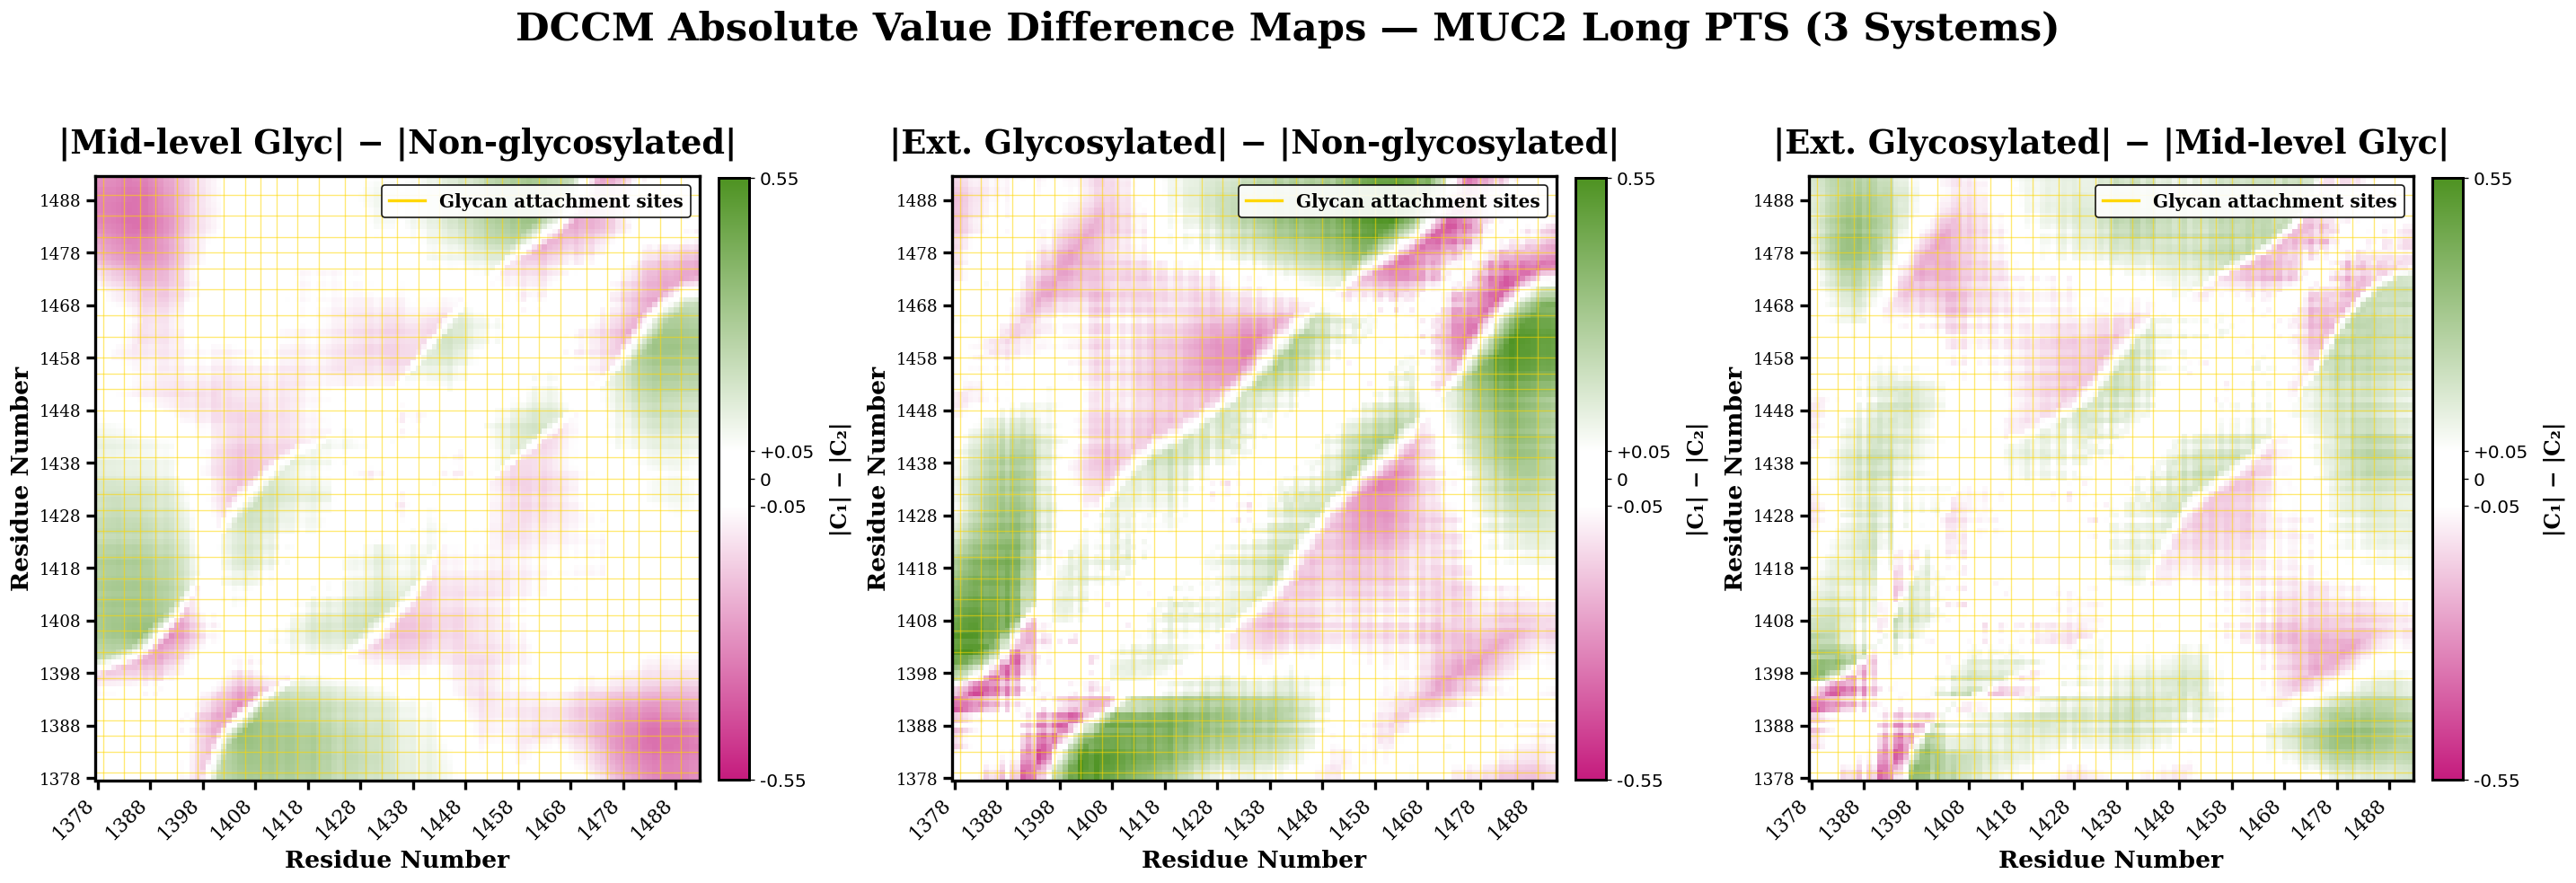

Saved combined: /home/computer2/analysis_simulations/analysis/dccm_glyc_noglyc/plots/dccm_absdiff_3sys.png


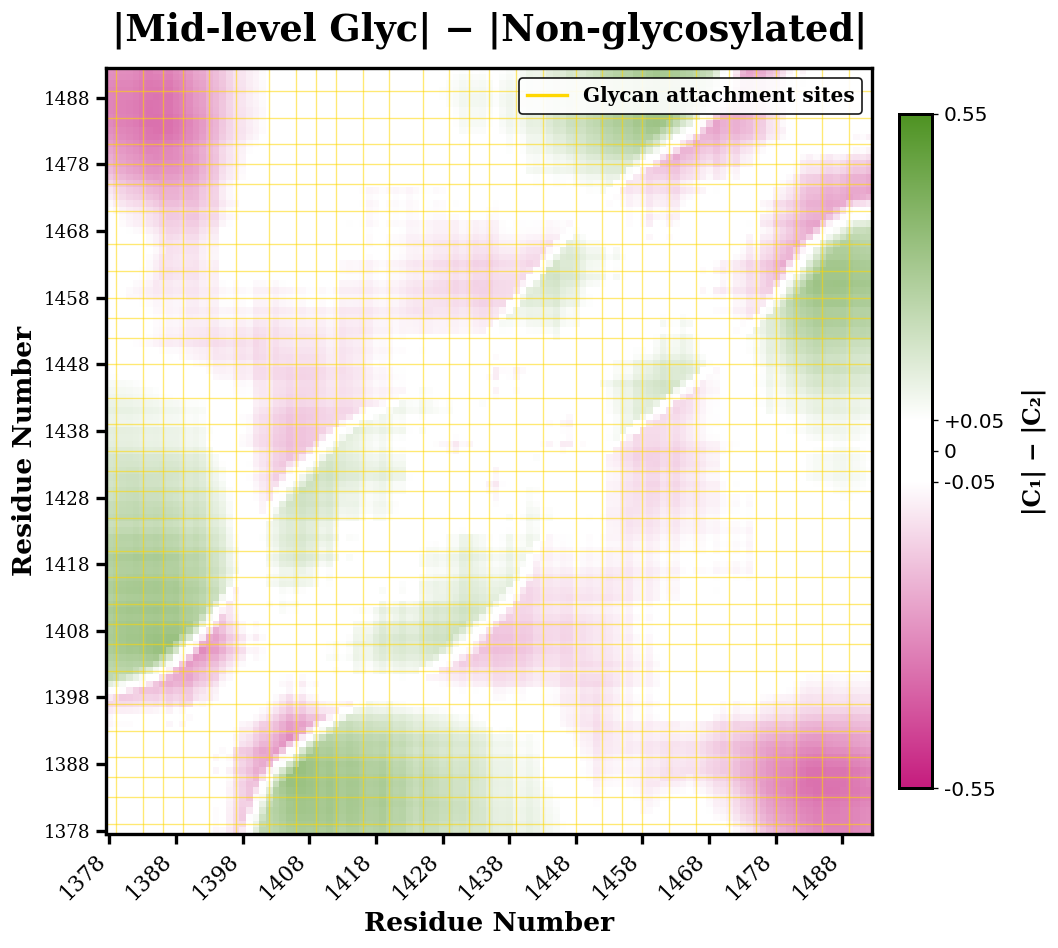

Saved: dccm_absdiff_gly_nog.png


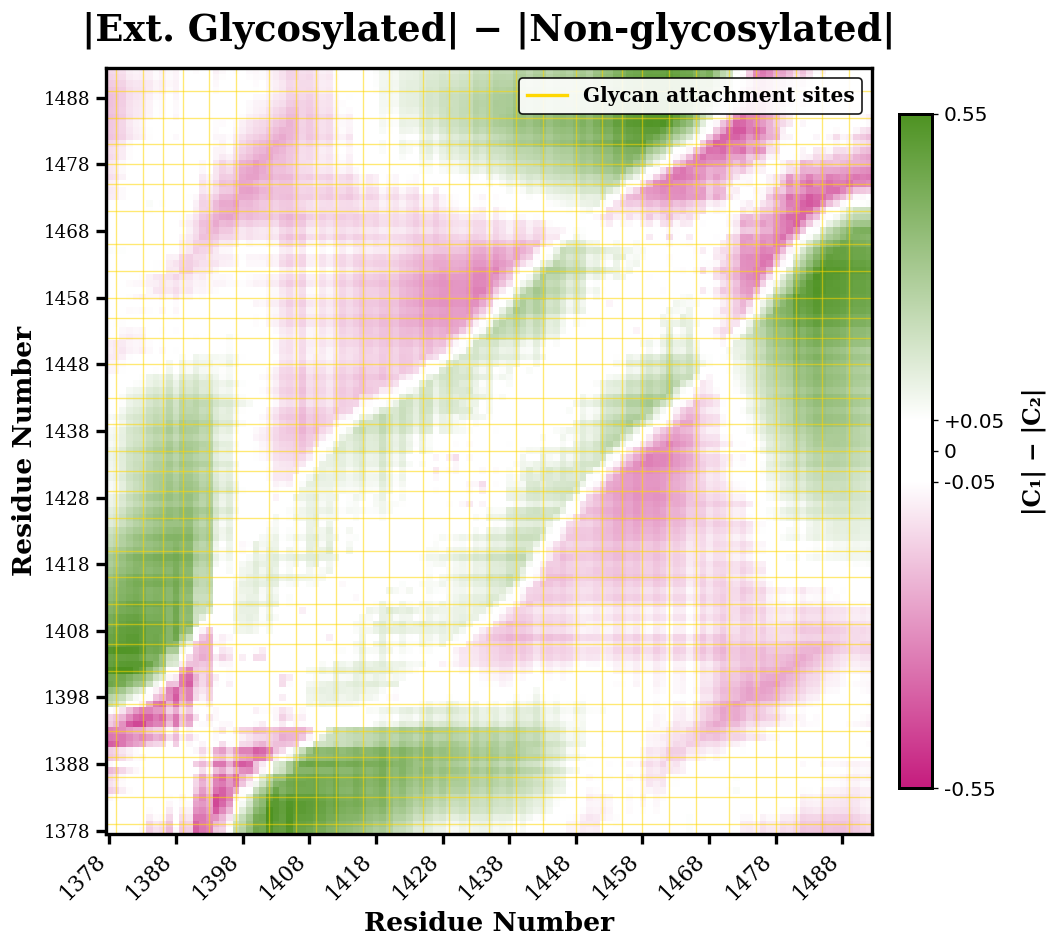

Saved: dccm_absdiff_ext_nog.png


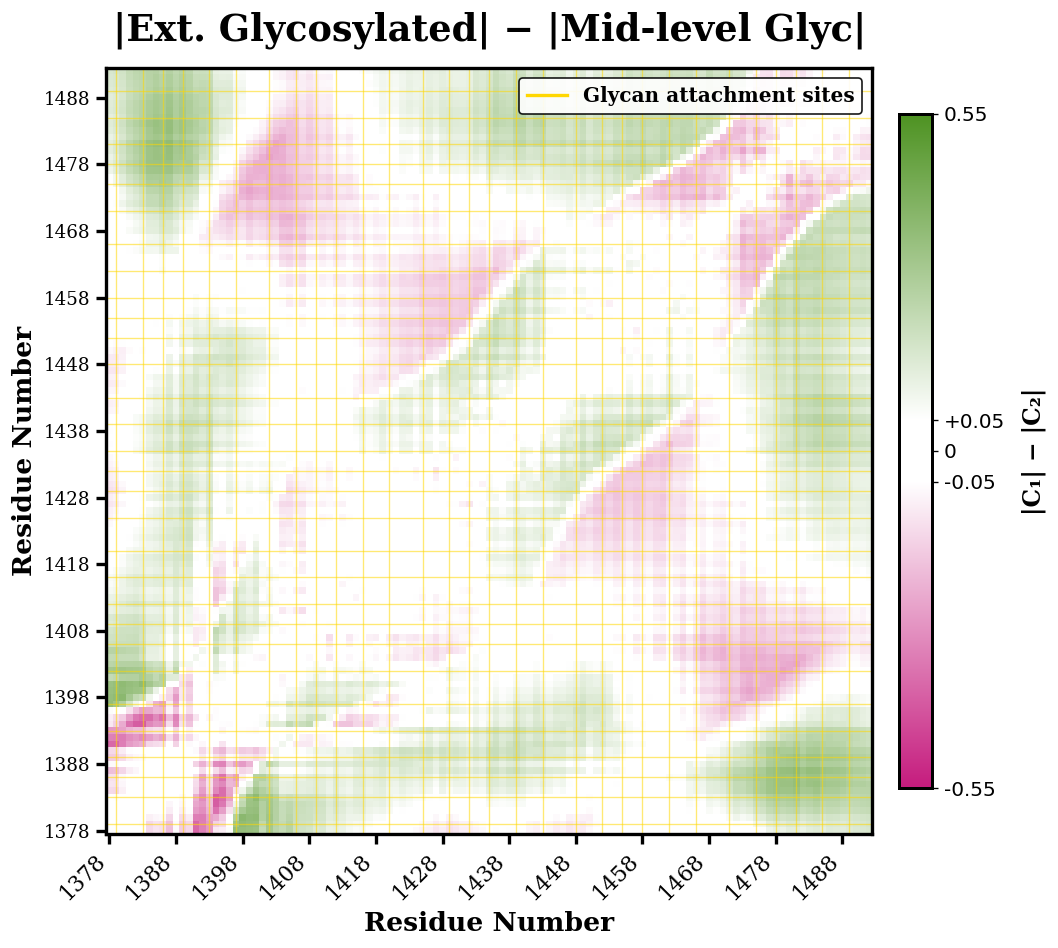

Saved: dccm_absdiff_ext_gly.png


In [13]:
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap

# Absolute value difference maps: |mat_A| - |mat_B|
# Positive = A has stronger correlation, Negative = B has stronger correlation
abs_panels = [
    (np.abs(dccm_gly) - np.abs(dccm_nog),
     "|Mid-level Glyc| − |Non-glycosylated|",
     "dccm_absdiff_gly_nog.png"),
    (np.abs(dccm_ext) - np.abs(dccm_nog),
     "|Ext. Glycosylated| − |Non-glycosylated|",
     "dccm_absdiff_ext_nog.png"),
    (np.abs(dccm_ext) - np.abs(dccm_gly),
     "|Ext. Glycosylated| − |Mid-level Glyc|",
     "dccm_absdiff_ext_gly.png"),
]

THRESHOLD = 0.05
tick_step = 10
tick_pos  = np.arange(0, N_RES, tick_step)
tick_labs = [str(res_nums[i]) for i in tick_pos]

vlim_all = max(np.abs(d).max() for d, *_ in abs_panels)

def make_cmap(vlim):
    lo_n = (vlim - THRESHOLD) / (2 * vlim)
    hi_n = (vlim + THRESHOLD) / (2 * vlim)
    return LinearSegmentedColormap.from_list("MWG_abs", [
        (0.0,  "#C51B7D"),
        (lo_n, "white"),
        (hi_n, "white"),
        (1.0,  "#4D9221"),
    ], N=2048)

# 3-panel combined
fig, axes = plt.subplots(1, 3, figsize=(24, 8), dpi=120)
fig.set_facecolor("white")

for ax, (abs_mat, title, fname) in zip(axes, abs_panels):
    cmap_abs = make_cmap(vlim_all)
    im = ax.imshow(abs_mat, cmap=cmap_abs, vmin=-vlim_all, vmax=vlim_all,
                   origin="lower", aspect="equal")
    for idx in glycan_idx:
        ax.axvline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
        ax.axhline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03, shrink=0.88)
    cbar.set_label("|C₁| − |C₂|", fontsize=14,
                   fontname="DejaVu Serif", fontweight="bold", labelpad=10)
    cbar.ax.tick_params(labelsize=12)
    cbar.set_ticks([-vlim_all, -THRESHOLD, 0, THRESHOLD, vlim_all])
    cbar.set_ticklabels([f"{-vlim_all:.2f}", f"-{THRESHOLD}", "0",
                         f"+{THRESHOLD}", f"{vlim_all:.2f}"])
    cbar.outline.set_linewidth(1.8)
    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_labs, rotation=45, ha="right",
                       fontsize=13, fontname="DejaVu Serif")
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(tick_labs, fontsize=11, fontname="DejaVu Serif")
    ax.set_xlabel("Residue Number", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=22, fontname="DejaVu Serif",
                 fontweight="bold", pad=16)
    ax.tick_params(length=6, width=2.0, direction="out")
    for spine in ax.spines.values():
        spine.set_linewidth(2.0)
    ax.legend(
        handles=[Line2D([0],[0], color="gold", linewidth=2.0,
                        label="Glycan attachment sites")],
        fontsize=12, loc="upper right", framealpha=0.90, edgecolor="black",
        prop={"family":"DejaVu Serif","size":12,"weight":"bold"})

fig.suptitle(
    "DCCM Absolute Value Difference Maps — MUC2 Long PTS (3 Systems)",
    fontsize=26, fontname="DejaVu Serif", fontweight="bold", y=1.03)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_absdiff_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved combined: {out}")

# Individual panels
for abs_mat, title, fname in abs_panels:
    fig2, ax2 = plt.subplots(figsize=(9, 8), dpi=120)
    fig2.set_facecolor("white")
    cmap_abs = make_cmap(vlim_all)
    im2 = ax2.imshow(abs_mat, cmap=cmap_abs, vmin=-vlim_all, vmax=vlim_all,
                     origin="lower", aspect="equal")
    for idx in glycan_idx:
        ax2.axvline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
        ax2.axhline(idx, color="gold", linewidth=0.8, alpha=0.55, zorder=2)
    cbar2 = plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.03, shrink=0.88)
    cbar2.set_label("|C₁| − |C₂|", fontsize=14,
                    fontname="DejaVu Serif", fontweight="bold", labelpad=10)
    cbar2.ax.tick_params(labelsize=12)
    cbar2.set_ticks([-vlim_all, -THRESHOLD, 0, THRESHOLD, vlim_all])
    cbar2.set_ticklabels([f"{-vlim_all:.2f}", f"-{THRESHOLD}", "0",
                          f"+{THRESHOLD}", f"{vlim_all:.2f}"])
    cbar2.outline.set_linewidth(1.8)
    ax2.set_xticks(tick_pos)
    ax2.set_xticklabels(tick_labs, rotation=45, ha="right",
                        fontsize=13, fontname="DejaVu Serif")
    ax2.set_yticks(tick_pos)
    ax2.set_yticklabels(tick_labs, fontsize=11, fontname="DejaVu Serif")
    ax2.set_xlabel("Residue Number", fontsize=16,
                   fontname="DejaVu Serif", fontweight="bold")
    ax2.set_ylabel("Residue Number", fontsize=16,
                   fontname="DejaVu Serif", fontweight="bold")
    ax2.set_title(title, fontsize=22, fontname="DejaVu Serif",
                  fontweight="bold", pad=16)
    ax2.tick_params(length=6, width=2.0, direction="out")
    for spine in ax2.spines.values():
        spine.set_linewidth(2.0)
    ax2.legend(
        handles=[Line2D([0],[0], color="gold", linewidth=2.0,
                        label="Glycan attachment sites")],
        fontsize=12, loc="upper right", framealpha=0.90, edgecolor="black",
        prop={"family":"DejaVu Serif","size":12,"weight":"bold"})
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, fname), dpi=300,
                bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {fname}")
